# Совместное появление участников в шоу продакшена "Medium Quality"

>**Контекст**
>
>Medium Quality — продакшн-компания, производящая развлекательный видеоконтент, наиболее известная такими проектами как "Что было дальше?", "Натальная карта", "Внутри Лапенко" и другими. Основана бывшим генеральным продюсером телеканала ТНТ Вячеславом Дусмухаметовым в 2016 году. Основным направлением работы продакшена было производство развлекательных проектов для YouTube, однако в конце 2022 года корпорация VK приобрела 51% продакшена, а в феврале 2023 было объявлено о переносе проектов Medium Quality с YouTube на платформу VK Видео. Позже, в 2024, году YouTube был заблокирован властями на территории РФ. Так, с начала 2023 года на платформе VK Видео активно публикуются многочисленные проекты Medium Quality.

В социальных сетях нередко иронизируют на тему однообразного контента Medium Quality: большинство популярных шоу эксплуатируют одинаковые форматы, задействуя в них одних и тех же медийных лиц. В этом блокноте мы проверим последнее утверждение и ответим на следующие вопросы:

- какие участники чаще остальных появляются в разных шоу?
- какие особенности имеет рассматриваемая социальная сеть?
- кто входит в число наиболее "популярных", или активных, участников сети?

> **Вывод**
>
> Анализ рассматривает участие 3324 человек в 168 проектах продакшена за период с марта 2022 по декабрь 2025 года.
> Участие в проектах сконцентрировано внутри небольшого круга медийных личностей (чаще всего комиков, так или иначе связанных с проектами телеканала ТНТ): топ-5 участников появлялись в >30% шоу продакшена, в то время, как 90% участников участвовали в 4% шоу и меньше. В число этих топ-5 вошли Игорь Джабраилов, Павел Дедищев, Гурам Амарян, Дмитрий Позов, Саша Ваш. Совокупно топ-1% участников (13 человек) участвовали в 80% шоу.
>Такая неоднородность в количестве появлений в шоу выражается в особенностях структуры социальной сети. Так, сеть имеет структуру small-world, где большинство участников имеет связь с любым другим через небольшое количество рукопожатий. Это обеспечивается во многом благодаря хабам -- чаще всего ведущих популярных шоу, которые в течение многих выпусков появляются вместе с другими участниками, либо участвуют в качестве приглашенного гостя. Такие участники имеют наибольшие значения мер центральности: degree, eigenvector, и betweenness.
> На основе количества выпусков и шоу, степени вершины и мер центральности удалось выделить 21 наиболее активных членов сети:
> - Азамат Мусагалиев
> - Александр Якушев
> - Александра Муратова
> - Алексей Шальнов
> - Андрей Бебуришвили
> - Антон Шастун
> - Арсений Попов
> - Варвара Щербакова
> - Гарик Харламов
> - Гурам Амарян
> - Денис Дорохов
> - Дмитрий Журавлев
> - Дмитрий Позов
> - Евгений Чебатков
> - Зоя Яровицына
> - Игорь Джабраилов
> - Илья Швецов
> - Павел Дедищев
> - Расул Чабдаров
> - Саша Ваш
> - Сергей Матвиенко
>
> Это участники, которые входят в топ-5% по количеству шоу и топ-1% хотя бы по 2 из 4 критериев: появлялись в большом количестве выпусков, имеют множество прямых связей и входят в число хабов, через них проходят кратчайшие пути между двумя другими участниками, они связаны с множеством других хабов.

Работа включает следующие этапы:
#### 1. Автоматизированный сбор данных.

Большим подспорьем при сборе данных стал сайт [Humorpedia](https://humorpedia.ru/medium-quality/), где перечислены проекты Medium Quality и ссылки на плейлисты с эпизодами шоу. Так как информация на сайте была не частично неактуальной, недостающие плейлисты были добавлены в датасет на основе принадлежности к каналам, которые перечислены на Humorpedia.

Сбор даных проходил в два этапа:
1) формирование списка шоу вручную с опорой на сайт Humorpedia
2) скрейпинг эпизодов указанных шоу с помощью самописного web-scraper'а ([ссылка на блокнот](https://github.com/liminovna/network-analysis-project/scraper.ipynb)). У ВК есть собственный API, но извлечь нужные данные в этой ситуации с помощью библиотеки `requests` было проще, чем использовать официальный API.
3) извлечение из описаний шоу и эпизодов ведущих и их гостей с помощью spacy, проверка и точечные дополнения/корректировки.

Данные в датасете актуальны на момент 2 декабря 2025 года. Продакшен также производит проекты и на других платформах -- они в датасет не вошли.

#### 2. Анализ и визуализация.

Анализ включает общее описание сети, определение хабов, структурный анализ,определение сообществ и клик.

В данной работе **вершинами** являются персоналии, а **ребрами** -- совместное появление в эпизоде. Граф является ненаправленным, гомогенным, взвешенным по количеству совместных появлений, или взаимодействий.

## Предобработка данных

In [72]:
#@title Импорт библиотек, декларация функций
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle

plt.style.use('ggplot')
palette = plt.color_sequences['Set3']
plt.set_cmap('Set3')

def display_palette():
    fig, ax = plt.subplots()
    for i, color in enumerate(palette):
        ax.add_patch(
            Rectangle(
                (i, 0),
                width=1,
                height=1,
                facecolor=color,
                edgecolor="white"
            )
        )

        # ax.text(
        #     i + 0.5,
        #     0.15,
        #     color,
        #     ha="center",
        #     va="top",
        #     fontsize=9,
        #     rotation=90
        # )

    ax.set_xlim(0, len(palette))
    ax.set_ylim(-0.5, 1)
    ax.axis("off")

    plt.tight_layout()
    plt.show()

def str2list(x: str) -> list:
    """
    Конвертировать строковое значение из поля guests_full в список.
    Если конвертация невозможна, вывести это значение.
    """
    try:
        if x is not np.nan:
            res = ast.literal_eval(x)
            return list(map(lambda s: s.strip(), res))
    except:
        print('error', x)

        return ['error']

def get_upper_iqr_threshold(series: pd.Series, coeff=1.5) -> float:
    """
    Посчитать верхний порог для нахождения выбросов
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    return q3 + coeff * iqr

total_stats = pd.DataFrame()

<Figure size 640x480 with 0 Axes>

### Загружаем данные
Собранные данные организованы в две таблицы:
- `data`: список эпизодов с указанием ведущих и гостей
    - `label` -- название лэйбла/канала (LABELSMART, Площадка, SlowSlowCow и др.)
    - `show_title` -- название шоу
    - `host_norm` -- ведущие
    - `link` -- ссылка на плейлист
    - `owner_id_y` -- id владельца плейлиста
    - `album_id` -- id плейлиста
    - `id` -- id видео
    - `title` -- название видео
    - `direct_url` -- ссылка на видео
    - `date` -- дата загрузки видео на платформу
    - `description` -- описание видео
    - `duration` -- длительность видео
    - `guests_full` -- список гостей
- `shows`: список шоу
    - `label` -- название лэйбла/канала (LABELSMART, Площадка, SlowSlowCow и др.)
    - `show_title` -- название шоу
    - `host_norm` -- ведущие
    - `link` -- ссылка на плейлист
    - `owner_id` -- id владельца плейлиста
    - `album_id` -- id плейлиста
    - `videos_count` -- количество видео в плейлисте
    - `status` -- предусмотрено ли участие "известных" гостей

In [73]:
#@title Загружаем данные из гитхаб-репозитория
!wget https://github.com/liminovna/network-analysis-project/raw/refs/heads/main/mq_data.xlsx

--2026-11-10 08:35:27--  https://github.com/liminovna/network-analysis-project/raw/refs/heads/main/mq_data.xlsx
Resolving github.com (github.com)... 20.27.177.113
Connecting to github.com (github.com)|20.27.177.113|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/liminovna/network-analysis-project/refs/heads/main/mq_data.xlsx [following]
--2026-11-10 08:35:29--  https://raw.githubusercontent.com/liminovna/network-analysis-project/refs/heads/main/mq_data.xlsx
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1490523 (1.4M) [application/octet-stream]
Saving to: ‘mq_data.xlsx.1’

mq_data.xlsx.1      100%[===================>]   1.42M  8.16MB/s    in 0.2s    

2026-11-10 08:35:30 (8.16 MB/s) - ‘mq_dat

In [74]:
#@title Читаем файл: лист `shows`
#@markdown Извлекаем данные о шоу: из этого файла нам понадобится только название шоу `show_title` и колонка `status`, на основе которой мы будем избавляться от эпизодов, для которых не получилось определить "известных" участников.
#@markdown Чистим список от шоу, где не удалось найти имена либо ведущих, либо гостей (в таблице для них не указан status), либо шоу публикуется не на вк видео.
df_shows = pd.read_excel('mq_data.xlsx', sheet_name='shows', engine='openpyxl')
print(f'Строк (= кол-во шоу): {df_shows.shape[0]}')
print(f'Столбцов: {df_shows.shape[1]}')
to_delete = df_shows[df_shows['status'].isna()]['show_title']
print(f'Количество шоу после удаления строк:{len(df_shows) - len(to_delete)}')

Строк (= кол-во шоу): 188
Столбцов: 10
Количество шоу после удаления строк:182


In [75]:
#@title Читаем файл: лист `data`
#@markdown Читаем данные о выпусках, удаляем нерелевантные записи
cols = ['label', 'show_title', 'host_norm',
       'link', 'album_id', 'videos_count', 'id',
       'owner_id_y', 'title', 'direct_url', 'adding_date', 'date',
       'description', 'duration', 'guests_full']
df = pd.read_excel('mq_data.xlsx', sheet_name='data', engine='openpyxl')[cols]
df['date'] = pd.to_datetime(df['date'],unit='s')

print(f'Строк (= кол-во выпусков): {df.shape[0]}')
print(f'Столбцов: {df.shape[1]}')

# удаляем нелевантные записи
to_delete_df = df[df['show_title'].isin(to_delete)]
df.drop(to_delete_df.index, inplace=True)

df.drop(df[(df['host_norm'].isna()) & (df['guests_full'].isna())].index, inplace=True)
df.drop(df[df['title'].isna()].index, inplace=True)
print('Осталось строк:', len(df))

Строк (= кол-во выпусков): 3378
Столбцов: 15
Осталось строк: 3324


## Разведочный анализ

Далее рассмотрим, какие данные нам доступны и составим общую картину об активности шоу и участников.

In [76]:
# @title Несколько строк из датасета
# @markdown Описание столбцов приведено выше
df.head()

,label,show_title,host_norm,link,album_id,videos_count,id,owner_id_y,title,direct_url,adding_date,date,description,duration,guests_full
1,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239354.0,-214484275.0,[Культурный Код] - БЕЛАРУСЬ | [Культурный Код] #2,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:34:37,"Продолжаем узнавать из первых уст о культурах,...",435.0,['Ирина Приходько']
2,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239353.0,-214484275.0,[Культурный Код] - МЕДИЦИНА | [Культурный Код] #3,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:34:18,"Продолжаем узнавать из первых уст о культурах,...",462.0,['Лука Хиникадзе']
3,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239352.0,-214484275.0,[Культурный Код] - САНКТ-ПЕТЕРБУРГ | [Культурн...,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:33:35,"Продолжаем узнавать из первых уст о культурах,...",509.0,['Всеволод Ловкачев']
4,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239351.0,-214484275.0,[Культурный Код] - BURNING MAN | [Культурный к...,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:32:53,"Продолжаем узнавать из первых уст о культурах,...",776.0,['Павел Сахаров']
5,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239350.0,-214484275.0,[Культурный Код] - ТАТУ | [Культурный код] #5,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:32:42,"Продолжаем узнавать из первых уст о культурах,...",412.0,['Евген Сердюк']


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3324 entries, 1 to 3377
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   label         3324 non-null   object        
 1   show_title    3324 non-null   object        
 2   host_norm     2985 non-null   object        
 3   link          3324 non-null   object        
 4   album_id      3324 non-null   object        
 5   videos_count  3324 non-null   int64         
 6   id            3324 non-null   float64       
 7   owner_id_y    3324 non-null   float64       
 8   title         3324 non-null   object        
 9   direct_url    3324 non-null   object        
 10  adding_date   3313 non-null   float64       
 11  date          3324 non-null   datetime64[ns]
 12  description   3300 non-null   object        
 13  duration      3290 non-null   float64       
 14  guests_full   2658 non-null   object        
dtypes: datetime64[ns](1), float64(4), int64(1),

In [78]:
#@title Пропущенные значения
pd.concat([df.isna().sum(), df.isna().sum() / len(df)], axis=1).rename(columns={0: 'missing_abs', 1: 'missing_rate'})

,missing_abs,missing_rate
label,0,0.000000
show_title,0,0.000000
host_norm,339,0.101986
link,0,0.000000
album_id,0,0.000000
videos_count,0,0.000000
id,0,0.000000
owner_id_y,0,0.000000
title,0,0.000000
direct_url,0,0.000000


Причины пропусков:
- `host_norm` может быть пропущен, когда у шоу нет постоянного ведущего/ведущих -- только приглашенные гости.
- `adding_date` и `duration` отсутствовал в некоторых ответах API. Причина этому неясна. Однако эти данные в дальнейшем анализе не пригодятся.
- `description` могло опускаться авторами намеренно.
- `guests_full` пропущен, когда формат шоу не предполагает участия "медийных" гостей.

In [79]:
#@title Проверяем на дубли
df[df.duplicated(subset=['show_title', 'owner_id_y', 'id'], keep=False)]

,label,show_title,host_norm,link,album_id,videos_count,id,owner_id_y,title,direct_url,adding_date,date,description,duration,guests_full


Датасет содержит информацию о 3324 эпизодах. В датасете присутствуют допустимые пропуски: 10% эпизодов не имеют указания ведущих, 20% -- гостей.

In [80]:
# подготавливаем к анализу столбцы с указнием ведущих и гостей
df['host_norm'] = df['host_norm'].str.lower()
df['hosts_str'] = df['host_norm']
df['guests_full'] = df['guests_full'].str.lower()
df['host_norm'] = df['host_norm'].str.split(',')
df['guests_full'] = df['guests_full'].apply(str2list)

### Активность каналов

Далее рассмотрим, когда были загружены выпуски, длительность шоу и когда запускались пилоты

In [81]:
#@title Каналы и количества шоу/выпусков
label_stats = df.groupby('label').agg({
    'show_title': 'nunique',
    'title': 'count',
    'date': 'min'
})\
.rename(columns={
    'show_title': 'show_count',
    'title': 'episode_count',
    'date': 'first_upload_date'
})\
.sort_values('episode_count', ascending=False)

label_stats['episode_count_ratio'] = label_stats['episode_count'].cumsum() / label_stats['episode_count'].sum()

label_stats[['show_count', 'episode_count', 'episode_count_ratio', 'first_upload_date']].style.set_caption('Каналы, количества шоу, выпусков и дата первой загрузки на вк видео')

,show_count,episode_count,episode_count_ratio,first_upload_date
label,,,,
ИМПРОКОМ,12,552,0.166065,2023-01-20 03:51:38
LABELSMART,27,399,0.286101,2023-01-23 08:47:25
easy com,10,332,0.385981,2023-01-19 18:50:00
LABELCOM,23,313,0.480144,2023-01-21 06:19:16
Площадка,11,243,0.553249,2022-04-05 10:19:57
Канал Азамата Мусагалиева,6,221,0.619735,2023-01-17 10:07:01
Комьюнити,9,210,0.682912,2023-02-27 06:25:26
vk видео,9,159,0.730746,2023-05-27 04:47:15
Парковка,9,151,0.776173,2023-07-02 08:05:29


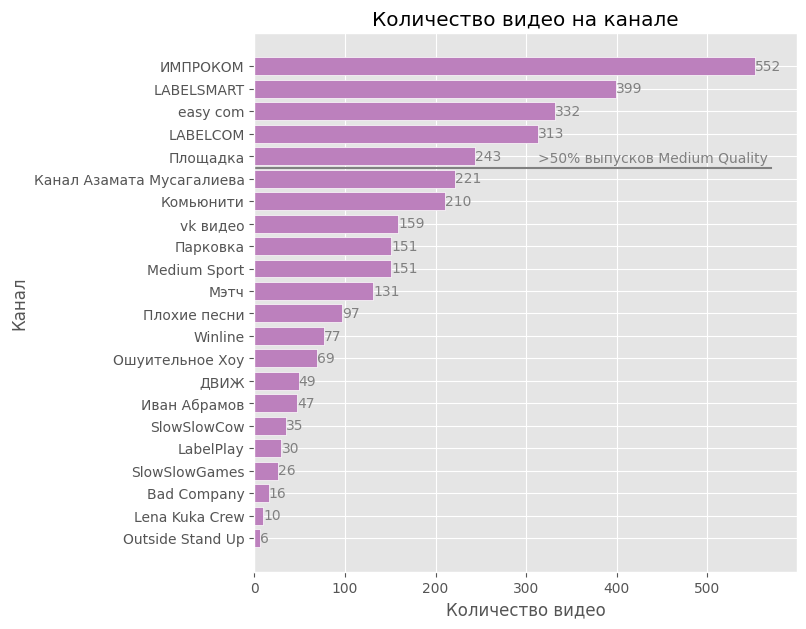

In [82]:
#@title Количество опубликованных выпусков

fig, ax = plt.subplots(figsize=(7,7))
# fig.subplots_adjust(wspace=0.05)

label_stats = label_stats.sort_values('episode_count', ascending=True)
bars = ax.barh(width=label_stats['episode_count'], y=label_stats.index, edgecolor='white', color=palette[9])
ax.bar_label(bars, fontsize=10, color='grey')

ax.set_title('Количество видео на канале')
ax.set(
    xlabel='Количество видео',
    ylabel='Канал',
)

trans = ax.get_xaxis_transform()
ax.annotate('>50% выпусков Medium Quality', xy=(440, 0.78), xycoords=trans, ha="center", va="top", color="grey")
ax.plot([1,570],[0.749, 0.749], color="grey", transform=trans, clip_on=False);

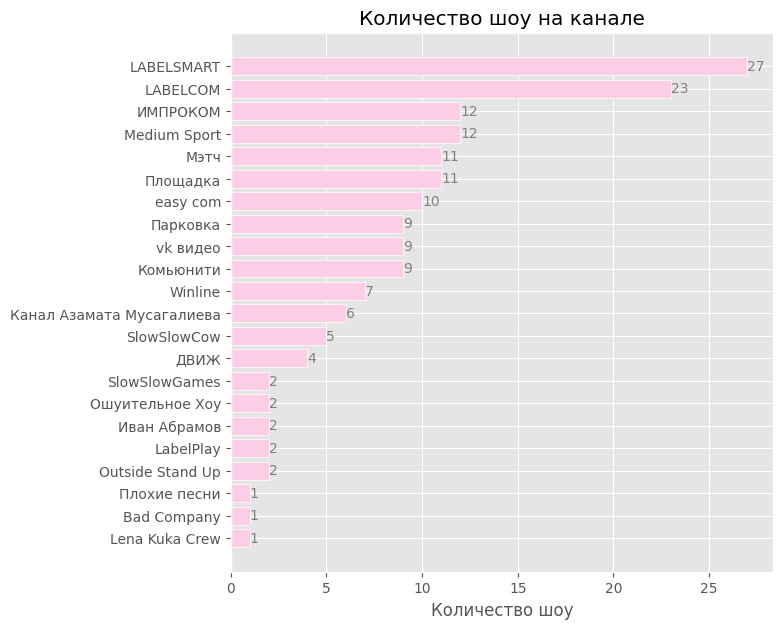

In [83]:
#@title Количество шоу
fig, ax = plt.subplots(figsize=(7,7))
label_stats = label_stats.sort_values('show_count', ascending=True)
bars = ax.barh(width=label_stats['show_count'], y=label_stats.index, edgecolor='white', color=palette[7])
ax.bar_label(bars, fontsize=10, color='grey')

ax.set_title('Количество шоу на канале')
ax.set(
    xlabel='Количество шоу',
);

In [84]:
#@title Шоу с наибольшим количеством выпусков (топ-5%)
show_stats = df.groupby(['label', 'show_title', 'hosts_str'])['title'].count().sort_values(ascending=False)
# threshold = get_upper_iqr_threshold(show_stats)
threshold = show_stats.quantile(0.95)
show_stats[show_stats>threshold]

,,,title
label,show_title,hosts_str,
ИМПРОКОМ,Контакты,антон шастун,131
Канал Азамата Мусагалиева,Большое шоу,азамат мусагалиев,113
ИМПРОКОМ,Громкий вопрос,"арсений попов,дмитрий позов,сергей матвиенко,антон шастун",109
easy com,Женский форум,"ольга парфенюк,варвара щербакова,наталья борисова,александра муратова",99
ИМПРОКОМ,Шоу Истории,"арсений попов,дмитрий позов,сергей матвиенко,антон шастун",92
vk видео,Кстати,"азамат мусагалиев,гарик харламов,денис дорохов",91
ИМПРОКОМ,Цитаты,"антон шастун,елизавета гончарова",70
Комьюнити,БЫЛОСЛОВО,павел дедищев,67
LABELSMART,Факты,"александр якушев,илья швецов",67


Более половины всех выпусков опубликовано на пяти каналах: LABELSMART LABELCOM, ИМПРОКОМ, easy com и Площадка.

Самыми "крупными" по количеству выпусков являются развлекательные шоу "Контакты" (ИМПРОКОМ), "Большое шоу" (Канал Азамата Мусагалиева), "Громкий вопрос" (ИМПРОКОМ), "Женский форум" (eays com), "Плохие песни" (SlowSlowCow), "Шоу Истории" (ИМПРОКОМ), "Цитаты" (ИМПРОКОМ) и "Кстати" (официальный канал вк видео).

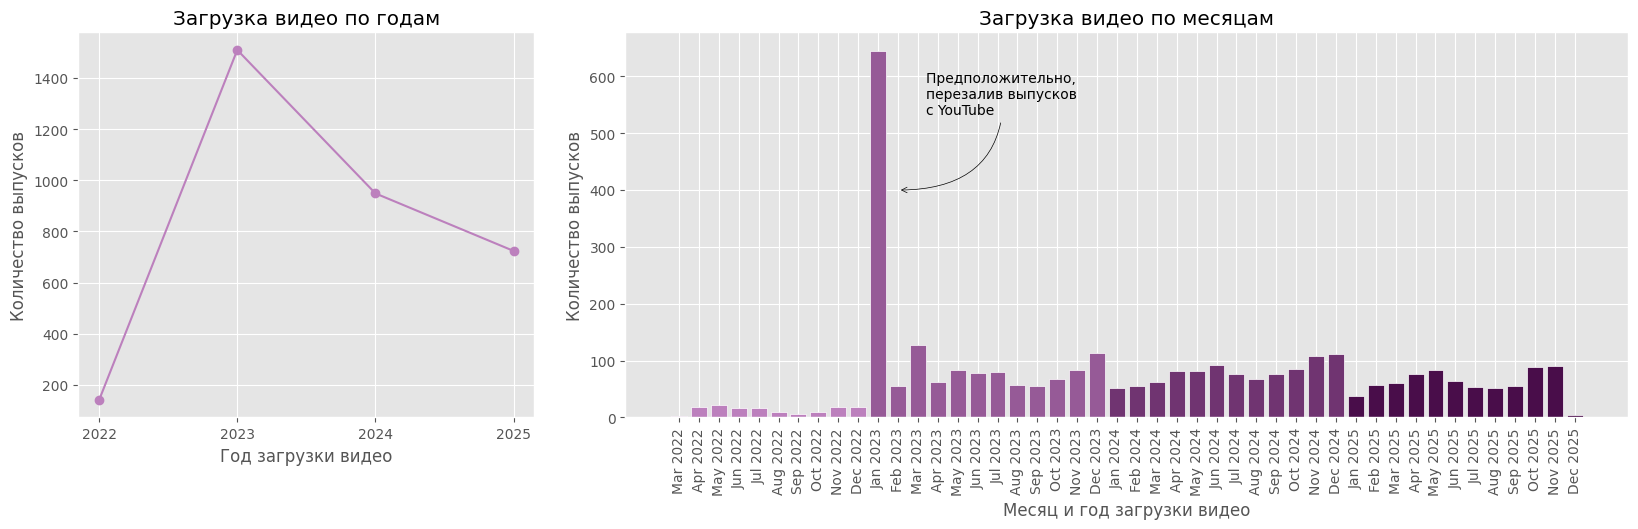

In [85]:
#@title Выход эпизодов по годам и месяцам
from matplotlib.gridspec import GridSpec

fig=plt.figure(figsize=(20,5))
gs=GridSpec(1,3) # 2 rows, 3 columns

# chart 1
ax0=fig.add_subplot(gs[0,0])

dates = df['date'].dropna().dt.year
labels, counts = np.unique(dates, return_counts=True)

xticks = np.arange(dates.min(), dates.max() + 1)
container = ax0.plot(labels, counts, marker='o', color=palette[9])

ax0.set_title('Загрузка видео по годам')
ax0.set(
    xlabel='Год загрузки видео',
    ylabel='Количество выпусков',
    xticks=xticks,
)

# chart 2
ax1=fig.add_subplot(gs[0,1:],)
dates = df['date'].dropna().dt.to_period('M').dt.start_time.sort_values()

dct = dict(zip(dates.astype(str).to_list(), dates.dt.strftime('%b %Y').to_list())) # optimize

d, counts = np.unique(dates.astype(str), return_counts=True)
labels = list(map(dct.get, d))
unique_years = dates.dt.year.unique()

# создаем палитру цветов
seq_colors = []
for i in range(4):
    new_color = tuple(map(lambda x: x-0.15*i, palette[9]))
    seq_colors.append(new_color)

color_map = dict(zip(unique_years, seq_colors))

bar_colors = list(map(color_map.get, d.astype('datetime64[Y]').astype(int) + 1970))
# dark_color = tuple(map(lambda x: x-0.15, palette[9]))
# bar_colors = list(map(lambda x: dark_color if x=='2023-01-01' else palette[9], d))
container = ax1.bar(x=labels, height=counts, edgecolor='white', color=bar_colors)

# ax1.bar_label(bars, fontsize=12, color='grey')

ax1.set_title('Загрузка видео по месяцам')
ax1.set(
    xlabel='Месяц и год загрузки видео',
    ylabel='Количество выпусков',
    xticks=labels,
    # rotation=90
)
ax1.tick_params("x", rotation=90)

ax1.annotate('Предположительно, \nперезалив выпусков\nс YouTube', xy=(11, 400), xycoords='data',
            xytext=(0.3, .9), textcoords='axes fraction',
            va='top', ha='left', color='black',
            arrowprops=dict(arrowstyle="->", connectionstyle="angle3", color='black'));

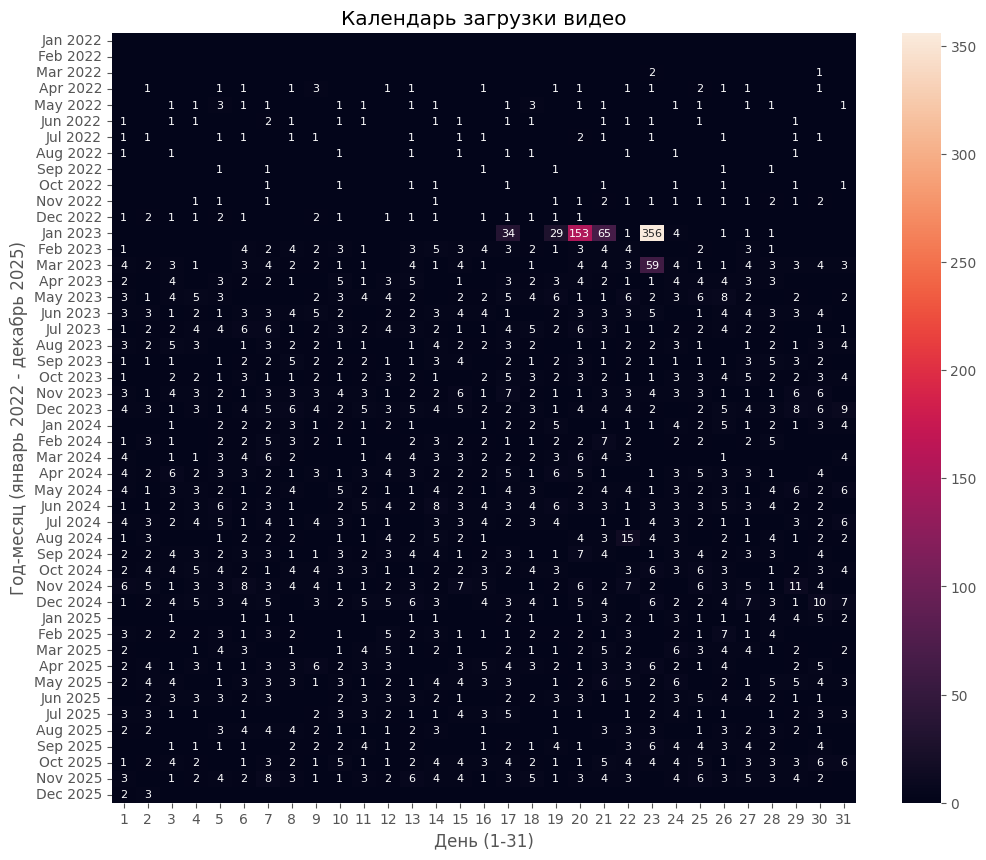

In [86]:
# @title Календарь публикации выпусков
import seaborn as sns
# создаем календарь дней за указанный период
all_dates = []
for y in range(2022, 2026):
    for m in range(1,13):
        for d in range(1,32):
            all_dates.append(y*10000+m*100+d)

# объединяем все дни с днями, когда были загружены видео
dates_df = pd.merge(
    left=pd.DataFrame(index=all_dates),
    right=df['date'].apply(lambda d: d.year*10000+d.month*100+d.day).value_counts().sort_index(),
    how='left',
    left_index=True,
    right_index=True
).fillna(0)
dates_df['year_month'] = dates_df.index//100
dates_df['day'] = dates_df.index%100


# визуализируем "календарь": по оси x -- дни, по оси y -- год и месяц
fig, ax = plt.subplots(figsize=(12,10))
pivot = dates_df.pivot(index="year_month", columns="day", values="count")
pivot.index = list(map(lambda x: pd.to_datetime(x, format='%Y%m').strftime('%b %Y'), pivot.index))

# в аннотации оставляем только значения >0
annotations = pivot.astype(int).where(
    pivot > 0,
    ""
)

# тепловая карта
sns.heatmap(data=pivot, annot=annotations, fmt='', annot_kws={"fontsize":8}, ax=ax)

ax.set_title('Календарь загрузки видео')
ax.set(ylabel='Год-месяц (январь 2022 - декабрь 2025)', xlabel='День (1-31)');

In [87]:
# @title Шоу, которые предположительно были массово перенесены в период с 17 по 23 января 2023 года
reupoads = df[(df['date']>'2023-01-17') & (df['date']<'2023-01-24')]['show_title'].value_counts().rename('reuploaded_videos')
reupoads[reupoads>1]

,reuploaded_videos
show_title,
Контакты,75
SEGOZAVTRA,47
История на ночь,46
Ошуительное Хоу,44
Что было дальше?,43
Громкий вопрос,35
Я себя знаю,34
Надкаст,32
#СОЗВОН,30


В январе 2023 года наблюдается пик по количеству загруженных видео -- возможно, тогда на платформу были загружены все выпуски, которые были ранее опубликованы на YouTube. По предположению, это  40 шоу, среди которых "Контакты", SEGOZAVTRA, "История на ночь", "Что было дальше?", "Громкий вопрос" и другие.

Также по календарю виден всплеск загрузок меньшего размера в конце марта: тогда на платформу было загружено 57 выпусков шоу "Плохие песни".

### Длительность шоу

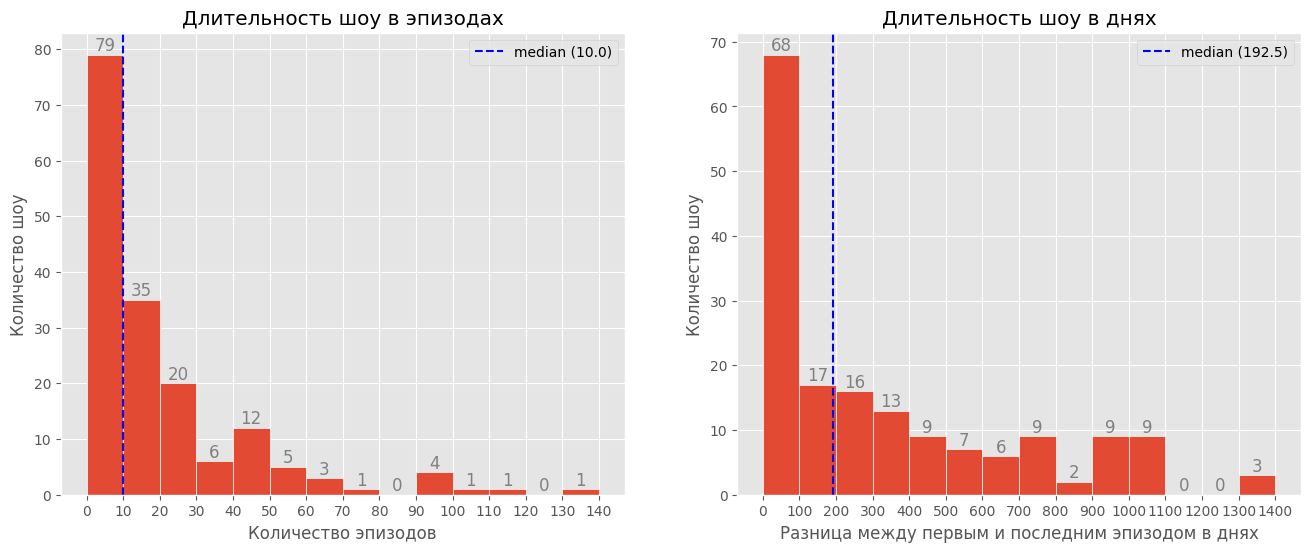

In [88]:
# @title Длительность в эпизодах и днях
# собираем информацию о времени загрузки первого и последнего выпуска для каждого шоу
aggregation_dict = {
    'date': ['min', 'max'],
    'id': 'count'
}
stats = df.groupby('show_title').agg(aggregation_dict)

# визуализируем длину шоу в эпизодах
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(8*2,6))
# fig, ax = plt.subplots(figsize=(8,6))

n_episodes = stats['id']['count']
bins = np.arange(0, n_episodes.max()+10, 10)
values, bins, bars = ax[0].hist(n_episodes, bins=bins, edgecolor='white')

ax[0].bar_label(bars, fontsize=12, color='grey')

ax[0].axvline(x=n_episodes.median(), color='b', linestyle='--', label=f'median ({round(n_episodes.median(), 2)})')

ax[0].set_title('Длительность шоу в эпизодах')
ax[0].set(xticks=bins, xlabel='Количество эпизодов', ylabel='Количество шоу')
ax[0].legend();

# визуализируем длину шоу в днях
intervals = (stats['date']['max'] - stats['date']['min']).dt.days
bins = np.arange(0, intervals.max()+100, 100)
values, bins, bars = plt.hist(intervals, bins=bins, edgecolor='white')

ax[1].bar_label(bars, fontsize=12, color='grey')

ax[1].axvline(x=intervals.median(), color='b', linestyle='--', label=f'median ({round(intervals.median(), 2)})')

ax[1].set_title('Длительность шоу в днях')
ax[1].set(xticks=bins, xlabel='Разница между первым и последним эпизодом в днях', ylabel='Количество шоу')
ax[1].legend();

### Участники проектов

In [89]:
#@title Извлекаем ведущих
hosts = df['hosts_str'].dropna().str.split(',').explode().str.strip()
hosts = hosts.rename('name')
print('Уникальных ведущих:', hosts.nunique())

Уникальных ведущих: 154


In [90]:
#@title Извлекаем гостей
guests = df['guests_full'].explode().str.strip()
guests = guests.rename('name')
print('Уникальных гостей:', guests.nunique())

Уникальных гостей: 1354


In [91]:
print('Участвовали только в качестве гостя:', len(list(set(guests.dropna()) - set(hosts.dropna()))))

Участвовали только в качестве гостя: 1228


In [92]:
#@title Топ-1% участников по количеству выпусков
# Объединяем оба списка -- ведущих и гостей -- в сет
all_pers = list(set(hosts.dropna()) | set(guests.dropna()))
print('Количество уникальных участников:', len(all_pers))

# Объединяем в одну последовательность, в которой считаем количество раз, человек участвовал в эпизодах в качестве ведущего или гостя
partic = pd.merge(left=hosts.value_counts().reset_index(name='count'), right=guests.value_counts().reset_index(name='count'), on='name', how='outer')
partic.columns = ['name', 'episodes_as_host', 'episodes_as_guest']
partic = partic.set_index('name')

partic['episodes_total'] = partic.sum(axis=1).astype(int)
partic['episodes_as_host'] = partic['episodes_as_host'].fillna(0).astype(int)
partic['episodes_as_guest'] = partic['episodes_as_guest'].fillna(0).astype(int)

total_stats = pd.concat([total_stats, partic], axis=1, join='outer')

# Проверяем, что все посчиталось правильно
assert partic.loc['зоя яровицына']['episodes_total'] == hosts.value_counts()['зоя яровицына'] + guests.value_counts()['зоя яровицына']

# визуализируем
top_1 = partic['episodes_total'].quantile(0.99)
top_1_data = partic.sort_values(by='episodes_total', ascending=False)[partic['episodes_total']>top_1]
print('Top-2% count:', len(top_1_data))
# top_1_data['as_host_ratio'] = top_1_data['episodes_as_host'] / top_1_data['episodes_total']
top_1_data['majority_role'] = np.where(top_1_data['episodes_as_host'] / top_1_data['episodes_total'] > 0.5, 'host', 'guest')
top_1_data.style.background_gradient(axis=0, cmap='YlOrRd')

Количество уникальных участников: 1382
Top-2% count: 14


/tmp/ipykernel_321/214929337.py:22: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



,episodes_as_host,episodes_as_guest,episodes_total,majority_role
name,,,,
антон шастун,606,88,694,host
дмитрий позов,568,69,637,host
азамат мусагалиев,345,48,393,host
денис дорохов,285,78,363,host
сергей матвиенко,270,74,344,host
игорь джабраилов,204,121,325,host
арсений попов,273,38,311,host
павел дедищев,199,97,296,host
роман косицын,170,78,248,host


In [93]:
partic.describe(percentiles=[0.25,0.5,0.75,0.9, 0.99])

,episodes_as_host,episodes_as_guest,episodes_total
count,1382.000000,1382.000000,1382.000000
mean,4.946454,5.232272,10.178726
std,31.820323,11.804786,40.054334
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,0.000000,1.000000,1.000000
75%,0.000000,4.000000,4.000000
90%,2.000000,11.000000,15.000000
99%,123.950000,69.190000,180.950000
max,606.000000,121.000000,694.000000


In [94]:
# @title Топ-1% гостей
guests_counts = guests.value_counts()
top_1perc_guests = guests_counts[guests_counts>guests_counts.quantile(0.99)]
if all(top_1perc_guests.index.isin(hosts.unique())):
    print('Все участники, входящие в топ-1% гостей, также ведут свои шоу')
else:
    print('В топ-1% входят участники, которые не ведут свои шоу')
top_1perc_guests

Все участники, входящие в топ-1% гостей, также ведут свои шоу


,count
name,
игорь джабраилов,121
павел дедищев,97
гурам амарян,90
антон шастун,88
зоя яровицына,87
роман косицын,78
денис дорохов,78
алексей сапрыкин,77
саша ваш,76


Распределение количества эпизодов, в которых появляются участники, сильно скошено вправо: медианное значение равно 1, а максимальное -- 694. **Топ-1% гостей -- ведущие других шоу**.

В числе лидеров по количеству "участий" стали члены "Импровизаторов" -- Антон Шастун (694 выпуска, топ-1), Дмитрий Позов (637 выпусков, топ-2), Сергей Матвиенко (344 выпуска, топ-5) и Арсений Попов (311 выпусков, топ-7) -- вместе они ведут шоу "Громкий вопрос", "Шоу Истории", а также участвуют в разных проектах по отдельности. Также в топ-3 и топ-4 вошли Азамат Мусагалиев (393 выпуска) и Денис Дорохов (363 выпуска) соответственно -- соведущие шоу "Кстати" и собственных проектов.


In [95]:
# @title Количество шоу, в которых появился каждый участник
# вычисляем, в какой доле шоу появлялся каждый участник

# Извлекаем ведущих
hosts = pd.merge(left=df['show_title'], right=df['hosts_str'].dropna().str.split(',').explode().str.strip(), left_index=True, right_index=True, how='right').drop_duplicates()
# hosts
# Извлекаем гостей
guests = pd.merge(left=df['show_title'], right=df['guests_full'].explode().str.strip(), left_index=True, right_index=True, how='right').drop_duplicates()
# guests
parctic_shows = pd.concat([hosts.rename(columns={'hosts_str': 'name'}), guests.rename(columns={'guests_full': 'name'})], ignore_index=True).drop_duplicates()
# parctic_shows

parctic_shows_agg = parctic_shows['name'].value_counts().rename('shows_total')
parctic_shows_agg = pd.concat([parctic_shows_agg, (parctic_shows['name'].value_counts() / df['show_title'].nunique()).rename('shows_ratio')], axis=1)

total_stats = pd.concat([total_stats, parctic_shows_agg], axis=1, join='outer')

parctic_shows_agg.describe(percentiles=[0.25,0.5,0.75,0.9,0.99])

,shows_total,shows_ratio
count,1382.000000,1382.000000
mean,3.539074,0.021066
std,7.035515,0.041878
min,1.000000,0.005952
25%,1.000000,0.005952
50%,1.000000,0.005952
75%,3.000000,0.017857
90%,7.000000,0.041667
99%,41.000000,0.244048
max,64.000000,0.380952


In [96]:
#@title Топ-20 по доле шоу, в которых они снимались
parctic_shows_agg.head(20)

,shows_total,shows_ratio
name,,
игорь джабраилов,64,0.380952
павел дедищев,63,0.375000
гурам амарян,55,0.327381
саша ваш,54,0.321429
дмитрий позов,53,0.315476
денис дорохов,49,0.291667
зоя яровицына,49,0.291667
расул чабдаров,48,0.285714
роман косицын,46,0.273810


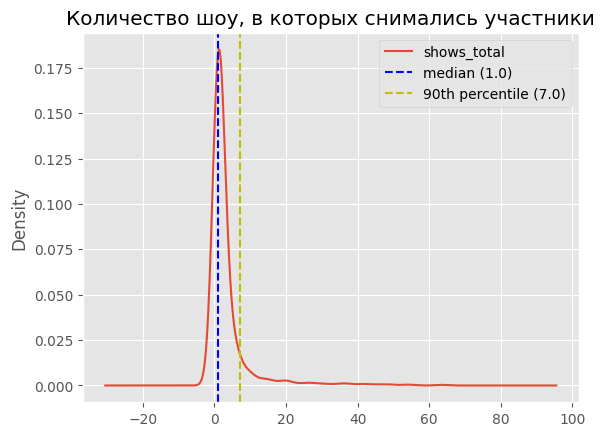

In [97]:
# @title Распределение количества шоу, в которых снимались участники
parctic_shows_agg['shows_total'].plot.kde()
plt.axvline(x=parctic_shows_agg['shows_total'].median(), color='b', linestyle='--', label=f'median ({round(parctic_shows_agg['shows_total'].median(), 2)})')
plt.axvline(x=parctic_shows_agg['shows_total'].quantile(0.90), color='y', linestyle='--', label=f'90th percentile ({round(parctic_shows_agg['shows_total'].quantile(0.90), 2)})')
plt.legend()
plt.title('Количество шоу, в которых снимались участники');

In [98]:
#@title Топ-1% по количеству шоу, в которых они участвовали
top1perc_shows = parctic_shows_agg['shows_ratio'][parctic_shows_agg['shows_ratio']>parctic_shows_agg['shows_ratio'].quantile(0.99)].index
# top5 = parctic_shows_ratios.head(5).index
r = parctic_shows[parctic_shows['name'].isin(top1perc_shows)]['show_title'].nunique() / df['show_title'].nunique()
print(f'Топ-1% ({len(top1perc_shows)} человек) совокупно участвовали в {r:.0%} шоу продакшена:')
print(*top1perc_shows, sep='\n')

Топ-1% (13 человек) совокупно участвовали в 83% шоу продакшена:
игорь джабраилов
павел дедищев
гурам амарян
саша ваш
дмитрий позов
денис дорохов
зоя яровицына
расул чабдаров
роман косицын
алексей сапрыкин
сергей матвиенко
антон шастун
иван абрамов


90% всех участников участвовали в 7 и менее шоу из 168. При этом топ-1% (13 человек) -- в 42 и более. Совокупно они участвовали в более, чем 83% шоу. Отдельно выделим "лидеров": Игорь Джабраилов, Павел Дедищев, Гурам Амарян, Саша Ваш и Дмитрий Позов появлялись в более чем в 30% всех шоу продакшена.

## Анализ социальной сети

Далее в качестве вершин выступают отдельно взятые персоналии, а в качестве ребер -- совместное появление в эпизоде, независимо от роли.

### Общее описание сети

In [99]:
import networkx as nx

In [100]:
#@title Подготавливаем список ребер
hosts = df['hosts_str'].dropna().str.split(',').explode().str.strip().rename('left')
guests = df['guests_full'].explode().str.strip().rename('right')
interactions = pd.merge(left=hosts, right=guests, left_index=True, right_index=True, how='inner')
interactions.drop(interactions[interactions['left']==interactions['right']].index, inplace=True)

# print('Количество парных взаимодействий (в т.ч. повторных): ', len(interactions))
# print('Количество уникальных пар: ', len(interactions.drop_duplicates()))

interactions = interactions.value_counts().reset_index()

In [101]:
# @title Создаем граф
G = nx.from_pandas_edgelist(
    df=interactions,
    source='left',
    target='right',
    edge_attr=['count'],
    # create_using=nx.MultiDiGraph,
)
print(G)

# считаем количество связанных компонент
components = list(nx.connected_components(G))
print("Количество связанных компонент:", len(components))
max_comp = max(components, key=len)
print("Размер наибольшей компоненты:", len(max_comp))
# print("Другие компоненты:")
# for c in components:
#     if c != max_comp:
#         print(c)

Graph with 1262 nodes and 6046 edges
Количество связанных компонент: 1
Размер наибольшей компоненты: 1262


Граф состоит из 1 262 вершин и 6046 ребер. Вся сеть представляет единую компоненту связанности.

#### Распределение степеней вершин

Минимальная степень вершины (взвешенная): 1
Максимальная степень вершины (взвешенная): 506


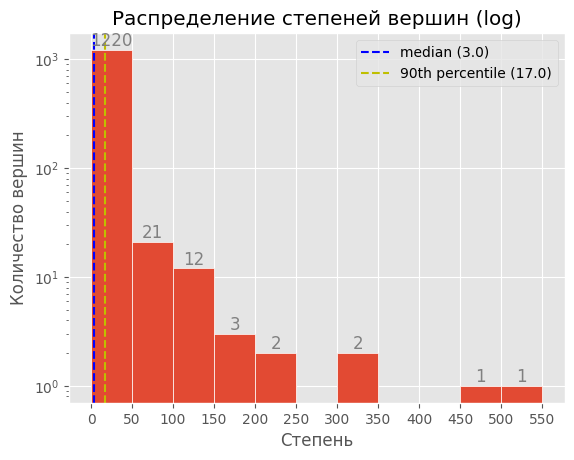

In [102]:
# @title Визуализация распределения степеней вершин
degree_seq = []
degree_dct = dict()
for (node, degree) in G.degree:
    degree_dct[node] = degree
    degree_seq.append(degree)

total_stats = pd.concat([total_stats, pd.Series(degree_dct).rename('degree_abs')], axis=1, join='outer')

bins, freq = np.unique(degree_seq, return_counts=True)
bins = np.arange(0, max(degree_seq)+50, 50)
values, bins, bars = plt.hist(degree_seq, edgecolor='white', align='mid', bins=bins, log=True)

plt.axvline(x=np.median(degree_seq), color='b', linestyle='--', label=f'median ({round(np.median(degree_seq), 2)})')
plt.axvline(x=np.quantile(degree_seq, 0.90), color='y', linestyle='--', label=f'90th percentile ({round(np.quantile(degree_seq, 0.90), 2)})')

plt.xticks(bins)
plt.bar_label(bars, fontsize=12, color='grey')
plt.xlabel('Степень')
plt.ylabel('Количество вершин')
plt.title('Распределение степеней вершин (log)')
plt.legend();

print('Минимальная степень вершины (взвешенная):', np.min(degree_seq))
print('Максимальная степень вершины (взвешенная):', np.max(degree_seq))

90% вершин имеет менее 17 связей.

Проверим, является ли сеть scale-free.

> Scale-free сеть это сеть, которая имеет степенное распределение. Это значит, что большинство вершин имеют небольшое количество связей (низкую степень), а крохотная часть вершин выполняют роль хабов, имея большое количество связей.

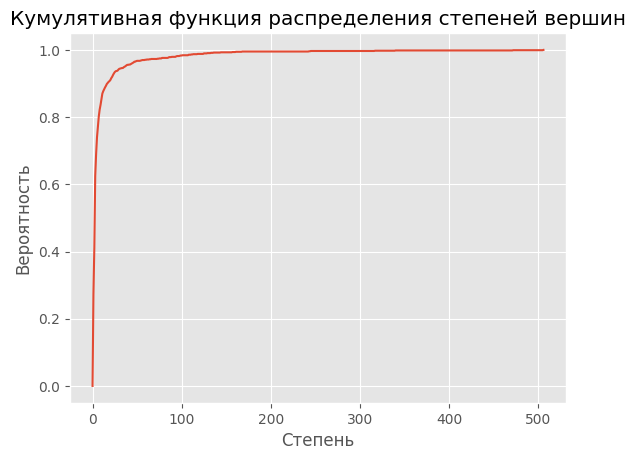

In [103]:
# @title Кумулятивная функция распределения степеней вершин
def empirical_cdf(g: nx.Graph):
    """
    Вычислить кумулятивную функцию распределения (CDF) степеней вершин
    """
    hist = nx.degree_histogram(g)
    return np.cumsum(hist) / np.sum(hist)

ecdf = empirical_cdf(G)

plt.plot(ecdf)
plt.xlabel('Степень')
plt.ylabel('Вероятность')
plt.title('Кумулятивная функция распределения степеней вершин')
plt.show();

Alpha = 2.248477908278899 r^2 = 0.9289999430585164


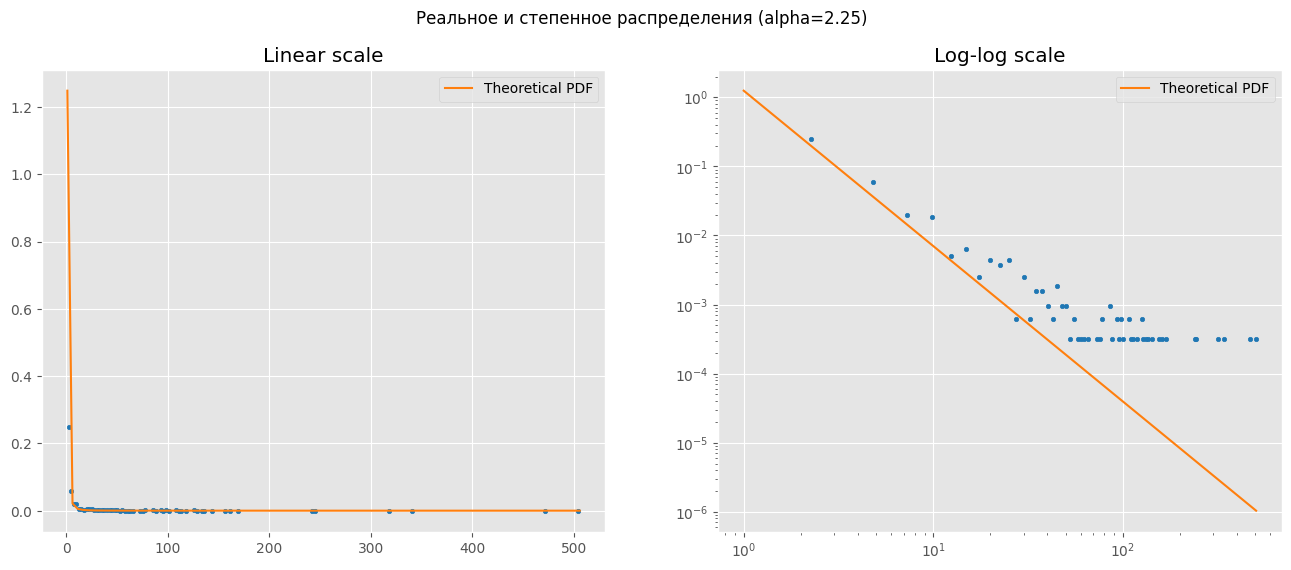

In [104]:
# @title Сравнение со степенным распределением
# Находим alpha
from sklearn.linear_model import LinearRegression

def alpha_lin_bins(x_train, bins):
    """
    Вычислить параметр alpha для степенного распределения
    """
    hist, bin_edges = np.histogram(x_train, bins=bins, density=True)
    bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2

    idx = np.argwhere(hist > 0)

    log_centers = np.log(bin_centers[idx][:,0]).reshape(-1, 1)
    log_hist = np.log(hist[idx])

    lr = LinearRegression().fit(log_centers, log_hist)
    return -lr.coef_[0][0], lr.score(log_centers, log_hist)

alpha, r2 = alpha_lin_bins(degree_seq, bins)
print('Alpha =', alpha, 'r^2 =', r2);

# Визуализируем
def power_law_pdf(x, alpha=3.5, x_min=1):
    C = (alpha - 1) / x_min ** (1 - alpha)
    return C * x ** (-alpha)

x_min = 1

x_space = np.linspace(min(degree_seq), max(degree_seq), 100)

fig, ax = plt.subplots(1,2, figsize=(16,6))

plt.suptitle(f'Реальное и степенное распределения (alpha={round(alpha,2)})')

hist, bin_edges = np.histogram(degree_seq, bins=200, density=True)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
ax[0].scatter(bin_centers[hist > 0], hist[hist > 0], s=10, c="tab:blue")
ax[0].plot(x_space, power_law_pdf(x_space, alpha, x_min), label='Theoretical PDF', c='tab:orange')
ax[0].legend()
ax[0].set_title('Linear scale')

hist, bin_edges = np.histogram(degree_seq, bins=200, density=True)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
ax[1].scatter(bin_centers, hist, s=10, c="tab:blue")
ax[1].plot(x_space, power_law_pdf(x_space, alpha, x_min),
         label='Theoretical PDF', c='tab:orange')
ax[1].legend()
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title('Log-log scale')

plt.show();

Высокое значение $R^2$ говорит о том, что прямая линия степенного распределения в логарифмическом масштабе объясняет 94% дисперсии $log⁡P(k)$ -- наше распределение степеней вершин очень близко к линейному в координатах log–log.

In [105]:
!pip install powerlaw

In [106]:
#@title Проверяем на следование степенной функции
import powerlaw

fit = powerlaw.Fit(degree_seq, discrete=True)

print()
print("Estimated alpha:", fit.alpha);

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 80/80 [00:00<00:00, 1272.59it/s]


Estimated alpha: 1.8887280791295455


In [107]:
#@title Проверяем на следование альтернативным распределениям
for alt in ["lognormal", "exponential", "stretched_exponential"]:
    R, p = fit.distribution_compare("power_law", alt, normalized_ratio=True)
    print(f'power_law vs.{alt}:', "R =", round(R, 2), "p =", round(p, 4), f'. "Выигрывает" {alt if R<0 else "power_law"}' if p < 0.05 else '')

power_law vs.lognormal: R = -1.82 p = 0.0688 
power_law vs.exponential: R = 5.79 p = 0.0 . "Выигрывает" power_law
power_law vs.stretched_exponential: R = -1.88 p = 0.0602 


/usr/local/lib/python3.13/dist-packages/powerlaw/distributions.py:776: UserWarning:

No valid fits found for distribution stretched_exponential.



Визуально наша сеть похожа на scale-free, т.к. степени вершин приближены  степенному распределению, однако мы не можем уверенно утверждать о такой принадлежности: статистические тесты не дали достаточного подтверждения этому. Поэтому мы можем охарактеризовать нашу сеть только как hub-dominated, скошенную вправо с несколькими участниками с большим количеством связей, где все остальные участники находятся как бы на периферии.

Сравним также нашу сеть с моделями Erdos–Renyi (случайной моделью), Barabasi–Albert и Watts–Strogatz.

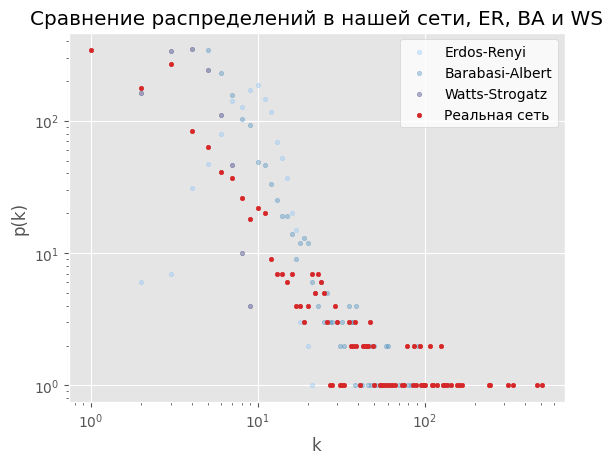

In [108]:
# @title Распределение степеней вершин нашей сети и модели ER, BA, WS
# ER
def random_from_real(graph):
    """
    Случайная сеть с параметрами нашей сети n (количество степеней) и p (вероятность связи)
    """
    n = len(graph.nodes)
    mean_degree = np.mean(list(dict(graph.degree).values()))
    p = mean_degree / (n - 1) # вероятность связи
    return nx.fast_gnp_random_graph(n, p)

ER = random_from_real(G)
degree_hist_ER = np.array(nx.degree_histogram(ER))
idx = np.argwhere(degree_hist_ER > 0)
plt.scatter(idx, degree_hist_ER[idx], s=10, label='Erdos-Renyi', c='xkcd:sky blue', alpha=0.3)


# BA
def estimate_m_from_graph(G):
    """
    Сеть, сгенерированная по модели Barabasi-Albert
    """
    # https://www.math.nagoya-u.ac.jp/~richard/teaching/s2024/SML_Adam_2.pdf
    N = G.number_of_nodes()
    E = G.number_of_edges()
    m_hat = E/N
    return round(m_hat)

BA = nx.barabasi_albert_graph(n=len(G.nodes), m=estimate_m_from_graph(G)) #
degree_hist_BA = np.array(nx.degree_histogram(BA))
idx = np.argwhere(degree_hist_BA > 0)
plt.scatter(idx, degree_hist_BA[idx], s=10, label='Barabasi-Albert', c='tab:blue', alpha=0.3)


# WS
def estimate_ws_params(degrees, tol=1e-5, max_iter=100):
    """
    Сеть, сгенерированная по модели Watts-Strogatz
    """
    n = len(degrees)
    mean_deg = np.mean(degrees)
    K = mean_deg / 2
    var = np.var(degrees, ddof=1)
    p_hat = binary_search_p(degrees, K, tol, max_iter)
    return n, K, p_hat

def binary_search_p(degrees, K, tol, max_iter):
    pl, pr = 0.0, 1.0
    for _ in range(max_iter):
        p = (pl + pr) / 2
        model_var = theoretical_ws_var(degrees, K, p)
        if abs(model_var - np.var(degrees, ddof=1)) < tol:
            return p
        if model_var > np.var(degrees, ddof=1):
            pr = p
        else:
            pl = p
    return p

def theoretical_ws_var(degrees, K, p):
    n = len(degrees)
    alpha = 0.5 * p * (n - 1 - 2 * K) / n
    beta = p / n
    mean = 2 * K
    second = 2 * K * (1 - 2 * alpha + 2 * beta)
    variance = second - mean**2
    return max(variance, 0)
n, K, p = estimate_ws_params(list(dict(G.degree).values()))

WS = nx.watts_strogatz_graph(n, int(K), p)
degree_hist_WS = np.array(nx.degree_histogram(WS))
idx = np.argwhere(degree_hist_WS > 0)
plt.scatter(idx, degree_hist_WS[idx], s=10, label='Watts-Strogatz', c='xkcd:dark blue', alpha=0.3)

# наша сеть
degree_hist = np.array(nx.degree_histogram(G))
idx = np.argwhere(degree_hist > 0)
plt.scatter(idx, degree_hist[idx], s=10, label='Реальная сеть', c='tab:red')


plt.legend(facecolor="white")
plt.xlabel('k')
plt.ylabel('p(k)')
plt.title('Сравнение распределений в нашей сети, ER, BA и WS')
plt.xscale('log')
plt.yscale('log')
plt.show();

In [109]:
# @title Проверим распределения с помощью теста Колмогорова-Смирнова.
from scipy.stats import ks_2samp

ER_degree_seq = [degree for (node, degree) in ER.degree]
print('p-value (ER) =', round(ks_2samp(degree_seq, ER_degree_seq).pvalue,4))

BA_degree_seq = [degree for (node, degree) in BA.degree]
print('p-value (BA) =', round(ks_2samp(degree_seq, BA_degree_seq).pvalue,4))

WS_degree_seq = [degree for (node, degree) in WS.degree]
print('p-value (WS) =', round(ks_2samp(degree_seq, WS_degree_seq).pvalue,4))


p-value (ER) = 0.0
p-value (BA) = 0.0
p-value (WS) = 0.0


Тест Колмогорова-Смирнова говорит о том, что распределение степеней вершин в нашей сети не сгенерировано ни одной из моделей (на уровне значимости 0.05). Однако это не значит, что ей не свойственно предпочтительное присоединение (чем больше у вершины связей, тем больше вероятность появления новых) или она имеет small-world структуры (большинство вершин могут быть достигнуты из любой другой вершины за малое количество шагов). Проверим это ниже.

#### Среднее расстояние (Average distance) и коэффициент кластеризации (Clustering coefficient)

Поскольку в сети есть вершины, между которыми нет ни прямой, ни опосредованной связи до некоторых других, для вычисления статистик выберем наибольшую компоненту связанности.

In [110]:
# @title Вычисляем свойства наибольшего подграфа
def select_largest_component(g: nx.Graph) -> nx.Graph:
    """
    Вернуть наибольший подграф
    """
    nodes = max(nx.connected_components(g), key=len)
    return g.subgraph(nodes)

G_sub = select_largest_component(G)
print('Вершин в подграфе:', len(G_sub.nodes()))
print('Ребер в подграфе:', len(G_sub.edges()))


c = {}
l = {}

l_ = nx.average_shortest_path_length(G_sub)
c_ = nx.average_clustering(G_sub)

c['Реальная сеть'] = c_
l['Реальная сеть'] = l_

print('Радиус: ', nx.radius(G_sub))
print('Диаметр: ', nx.diameter(G_sub))
print('Средняя длина кратчайшего пути: ', l_)
print('Срединй коэффициент кластеризации: ', c_)

Вершин в подграфе: 1262
Ребер в подграфе: 6046
Радиус:  3
Диаметр:  5
Средняя длина кратчайшего пути:  2.758022900849702
Срединй коэффициент кластеризации:  0.5209286157469315


In [111]:
# @title Сраваем с коэффициентами кластеризации и длинами кратчайшего пути моделей ER, BA, WS
for m_ in ['ER', 'BA', 'WS']:
    m = eval(m_)
    # print('Радиус: ', nx.radius(m))
    # print('Диаметр: ', nx.diameter(m))
    c_ = nx.average_clustering(m)
    l_ = nx.average_shortest_path_length(m)

    c[m_] = c_
    l[m_] = l_
    print(f'Средняя длина кратчайшего пути в {m_}: ', round(l_,4))
    print(f'Срединй коэффициент кластеризации в {m_}: ', round(c_, 4))
    print()

Средняя длина кратчайшего пути в ER:  3.4041
Срединй коэффициент кластеризации в ER:  0.0074

Средняя длина кратчайшего пути в BA:  3.0681
Срединй коэффициент кластеризации в BA:  0.0334

Средняя длина кратчайшего пути в WS:  5.5292
Срединй коэффициент кластеризации в WS:  0.0017



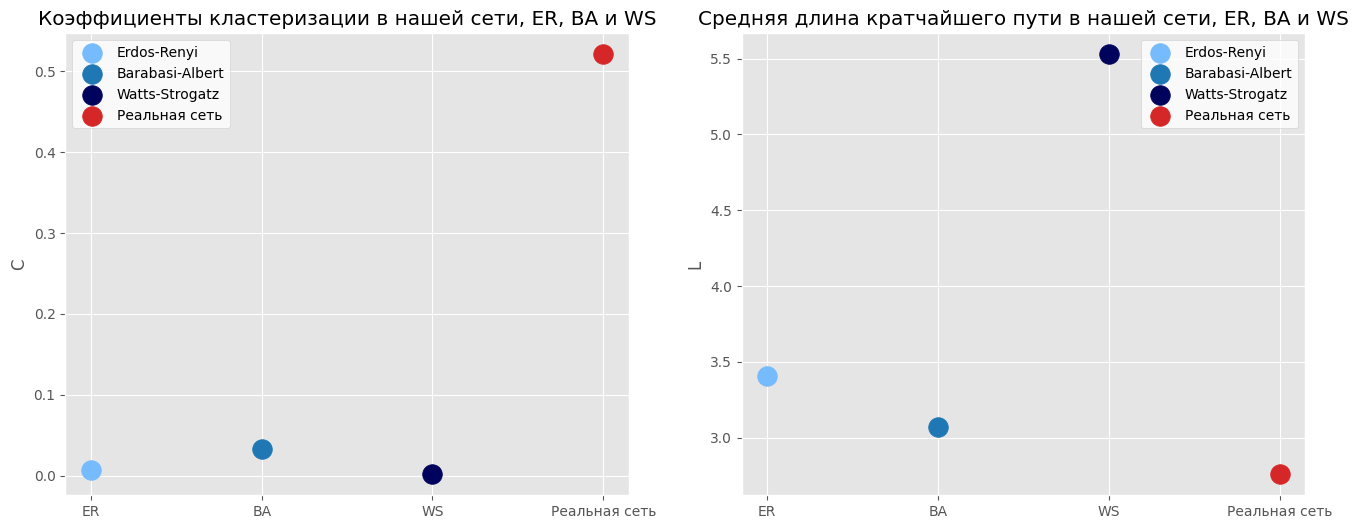

In [112]:
# @title Коэффициенты кластеризации и средняя длина пути
fix, ax = plt.subplots(1,2, figsize=(16,6))

ax[0].scatter('ER', c['ER'], s=200, label='Erdos-Renyi', c='xkcd:sky blue')
ax[0].scatter('BA', c['BA'], s=200, label='Barabasi-Albert', c='tab:blue')
ax[0].scatter('WS', c['WS'], s=200, label='Watts-Strogatz', c='xkcd:dark blue')
ax[0].scatter('Реальная сеть', c['Реальная сеть'], s=200, c='tab:red', label='Реальная сеть')

ax[0].legend(facecolor="white")
# plt.xlabel('k')
ax[0].set_ylabel('C')
ax[0].set_title('Коэффициенты кластеризации в нашей сети, ER, BA и WS')



ax[1].scatter('ER', l['ER'], s=200, label='Erdos-Renyi', c='xkcd:sky blue')
ax[1].scatter('BA', l['BA'], s=200, label='Barabasi-Albert', c='tab:blue')
ax[1].scatter('WS', l['WS'], s=200, label='Watts-Strogatz', c='xkcd:dark blue')
ax[1].scatter('Реальная сеть', l['Реальная сеть'], s=200, c='tab:red', label='Реальная сеть')

ax[1].legend(facecolor="white")
# plt.xlabel('k')
ax[1].set_ylabel('L')
ax[1].set_title('Средняя длина кратчайшего пути в нашей сети, ER, BA и WS')


plt.show();

Нашу сеть можно назвать small-world, поскольку ей свойственна высокая степень кластеризации и короткие расстояния между вершинами, вероятнее всего, благодаря хабам.
Высокий коэффициент кластеризации говорит о наличии небольших групп, которые часто появляются вместе: если A снимался в одном выпуске вместе с B и C, то B и C также снимаются вместе.

#### Определение хабов

Хабы выполняют роль связующего звена и имеют гораздо больше соединений, чем "средняя" вершина в сети. Хабы мы определим как вершины, которые имеют аномально высокие степени -- выбросы, находящиеся на расстоянии 5 стандартных отклонений от 75-го перцентиля.

In [113]:
# @title Находим хабы
degrees = pd.Series(dict(G.degree(weight='count'))).rename('degree').sort_values(ascending=False)

hub_degree_threshold = get_upper_iqr_threshold(degrees, coeff=5)
print('Минимально возможная степень хаба:', hub_degree_threshold)

hubs = degrees[degrees>=hub_degree_threshold]
print('Количество хабов:', len(hubs))
print('Хабы (со указанием степени вершины):')
print(hubs)

Минимально возможная степень хаба: 38.0
Количество хабов: 93
Хабы (со указанием степени вершины):
азамат мусагалиев    1604
денис дорохов         702
дмитрий позов         510
антон шастун          473
павел дедищев         444
                     ... 
дмитрий журавлёв       40
дмитрий шпеньков       40
надежда сысоева        39
евгения медведева      38
габар                  38
Name: degree, Length: 93, dtype: int64


In [114]:
#@title Топ-1% по количеству связей
degrees[degrees>=degrees.quantile(0.99)]

,degree
азамат мусагалиев,1604
денис дорохов,702
дмитрий позов,510
антон шастун,473
павел дедищев,444
гарик харламов,416
александр якушев,313
алексей щербаков,291
илья швецов,268
игорь джабраилов,242


#### Визуализация

Изначальное количество вершин: 1262
Количество вершин в сокращенном графе: 327
Минимальная степень вершины: 8.0


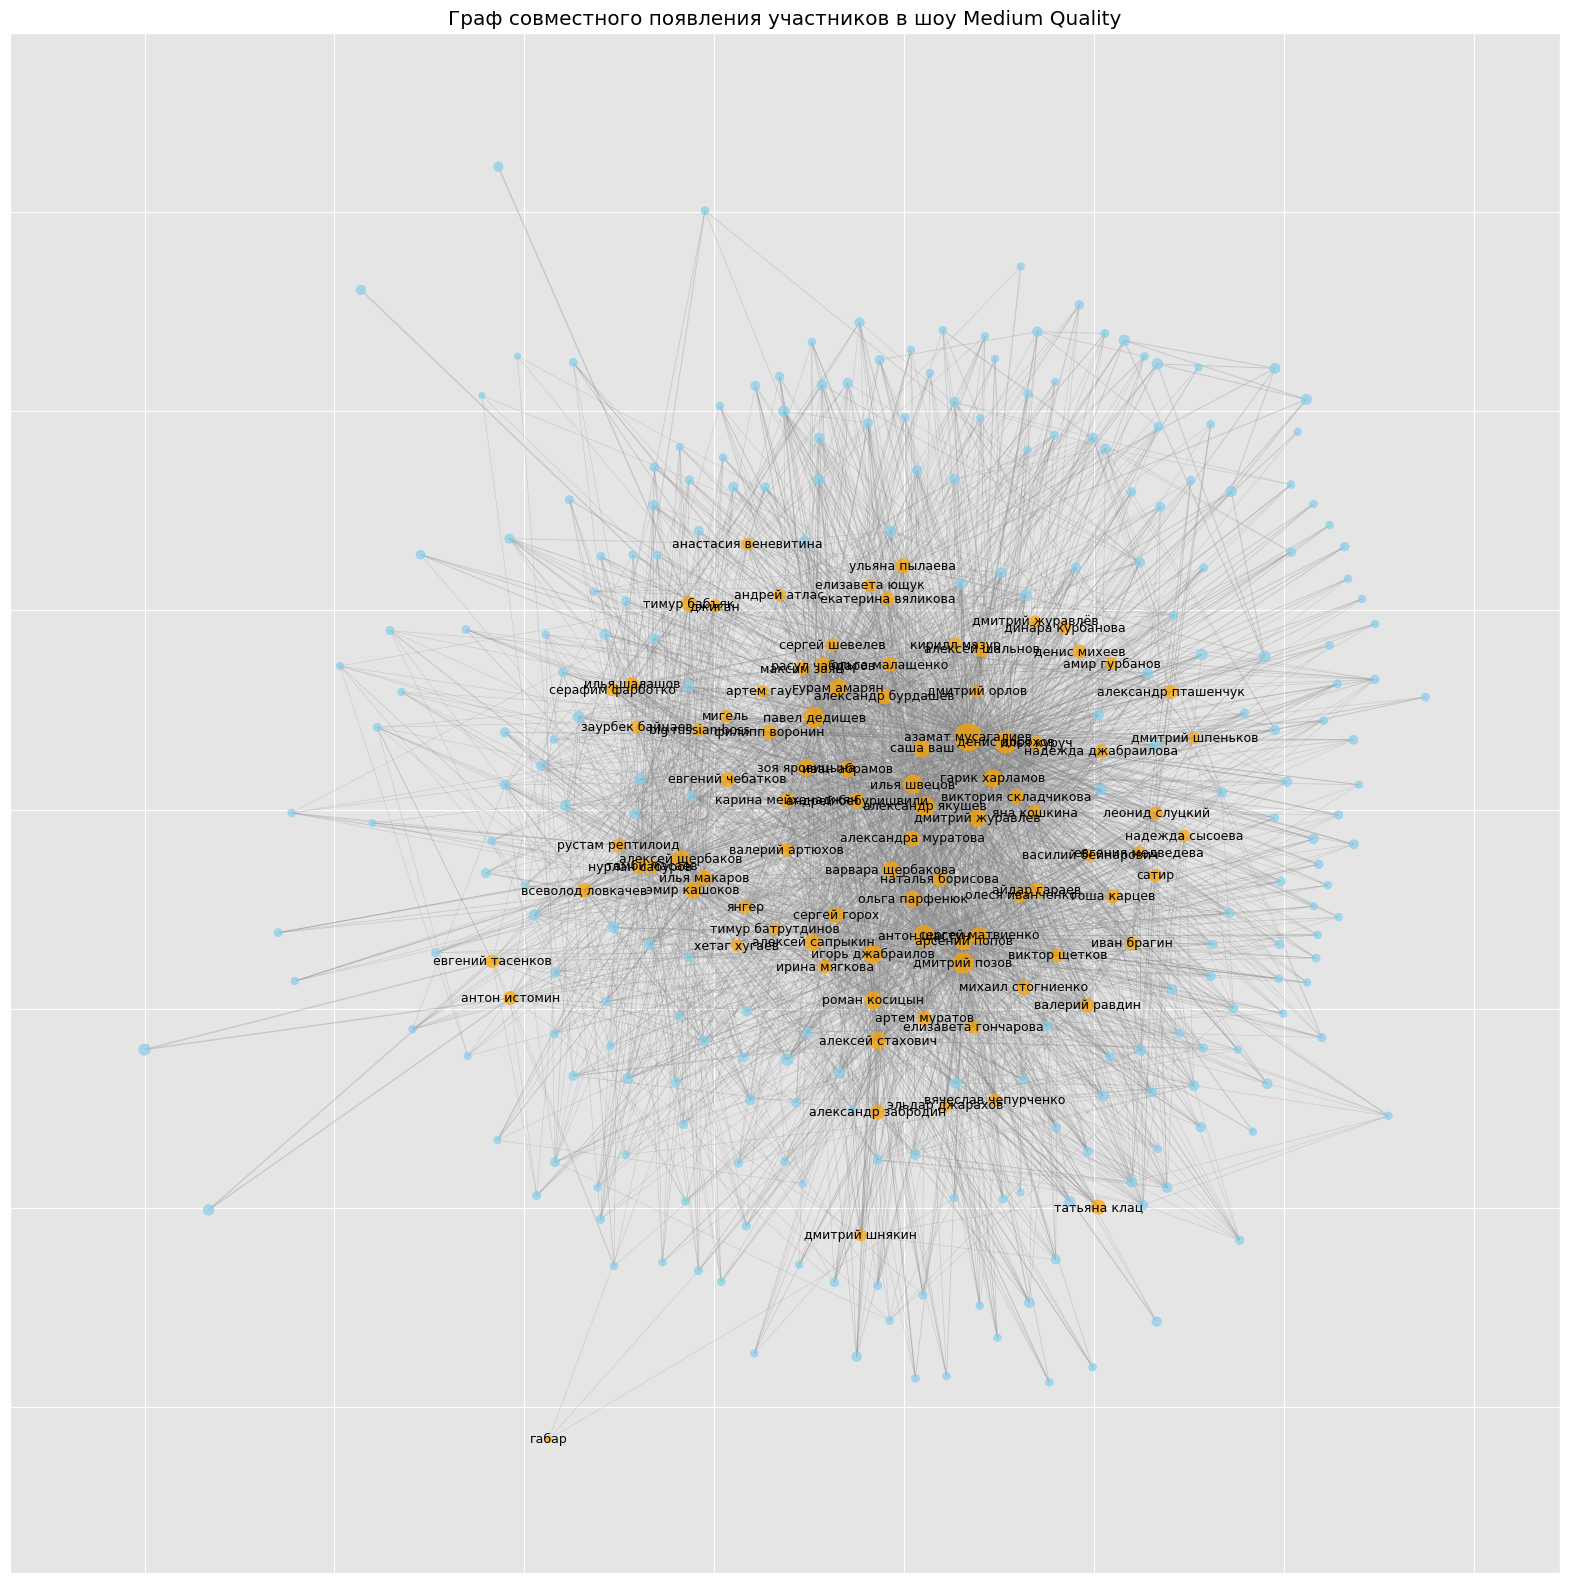

In [115]:
# @title Визуализация сети
# чтобы облегчить визуализацию, оставим только вершины, входящие в 75-й перцентиль по степени вершины
threshold = degrees.quantile(0.75)  # for example

keep_nodes = degrees[degrees >= threshold].index
G_vis = G.subgraph(keep_nodes)

print(f"Изначальное количество вершин: {G.number_of_nodes()}")
print(f"Количество вершин в сокращенном графе: {G_vis.number_of_nodes()}")
print(f"Минимальная степень вершины: {threshold}")

pos = nx.kamada_kawai_layout(G_vis)
# на визуализации будут отражены и выделены цветом только имена "хабов"
labels = {}
color_map = []
for node in G_vis.nodes():
    if node in hubs:
        labels[node] = node
        color_map.append('orange')
    else:
        color_map.append('skyblue')
# pos = nx.forceatlas2_layout(G_2025, scaling_ratio=200)

plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_vis, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_vis.degree(weight='count')).values()], alpha=0.7, node_color=color_map)
nx.draw_networkx_edges(G_vis, pos, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_vis, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_vis, pos,labels,font_size=9,font_color='black')

plt.title("Граф совместного появления участников в шоу Medium Quality")
plt.show();

Так как вершин и ребер слишком много, визуализировать граф статично на плоскости недостаточно. Создадим интерактивную сеть в другой конфигурации с помощью библиотеки ploty.

In [116]:
# @title Визуализация в plotly (сохраняется в файл `plotly_network.html`)
import plotly.graph_objects as go


edge_x = []
edge_y = []
for edge in G_vis.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_x.append(x0)
    edge_x.append(x1)
    edge_x.append(None)
    edge_y.append(y0)
    edge_y.append(y1)
    edge_y.append(None)

edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    line=dict(width=1, color='rgba(0.5, 0.5, 0.5, 0.3)'),
    hoverinfo='none',
    mode='lines')

node_x = []
node_y = []
colors = []

for node in G_vis.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)
    if node in hubs:
        colors.append('orange')
    else:
        colors.append('skyblue')

node_trace = go.Scatter(
    x=node_x, y=node_y,
    mode='markers',
    hoverinfo='text',
    marker=dict(
        # showscale=True,
        # colorscale='YlGnBu',
        # reversescale=True,
        color=colors,
        size=5,
        # colorbar=dict(
        #     thickness=15,
        #     title=dict(
        #       text='Node Connections',
        #       side='right'
        #     ),
        #     xanchor='left',
        # ),
        line_width=2))
node_adjacencies = []
node_text = []
# for node, adjacencies in enumerate(G.adjacency()):
#     node_adjacencies.append(np.log(len(adjacencies[1])))
#     # node_text.append('# of connections: '+str(len(adjacencies[1])))
#     node_text.append(adjacencies[0])

for p, d in dict(G_vis.degree(weight='count')).items():
    node_adjacencies.append(np.log(d)**2)
    node_text.append(p)

# node_trace.marker.color = node_adjacencies
node_trace.text = node_text
node_trace.marker.size = node_adjacencies
import plotly.graph_objects as go

fig = go.Figure(data=[edge_trace, node_trace],
             layout=go.Layout(
                title=dict(
                    text="Граф совместного участников на проектах Medium Quality",
                    font=dict(
                        size=16
                    ),
                ),
                height=1200,
                width=1600,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(
                    showarrow=True,
                    xref="paper", yref="paper",
                    x=0.005, y=-0.002 ) ],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )
# fig.show();
fig.write_html("plotly_network.html")

### Структурный анализ

#### Центральность (Centrality measures)
- `degree`: измеряет количество прямых связей.
- `betweenness`: чем выше значение, тем чаще через вершину пролегает кратчайший путь между другими вершинами.
- `closeness`: как быстро вершина может достигнуть любой другой вершины.
- `eigenvector`: измеряет количество связей с другими вершинами, имеющими много прямых связей.

Рассмотрим меры центральности нашей сети и выделим участников с наибольшими значениями мер.

In [117]:
#@title Вычисляем меры центральности
degrees_c = pd.DataFrame(dict(nx.degree_centrality(G)).items(), columns=('name', 'degree')).set_index('name')

betweenness_c = pd.DataFrame(dict(nx.betweenness_centrality(G, weight="count")).items(), columns=('name', 'betweenness')).set_index('name')

closeness_c = pd.DataFrame(dict(nx.closeness_centrality(G)).items(), columns=('name', 'closeness')).set_index('name')

eig_c = pd.DataFrame(dict(nx.eigenvector_centrality(G, weight="count")).items(), columns=('name', 'eigenvector')).set_index('name')

centralities = pd.concat([degrees_c, betweenness_c, closeness_c, eig_c],axis=1)
total_stats = pd.concat([total_stats, centralities], axis=1, join='outer')
print(centralities.head())

                     degree  betweenness  closeness  eigenvector
name                                                            
азамат мусагалиев  0.401269     0.163720   0.604506     0.570541
зоя яровицына      0.105472     0.043127   0.496457     0.079032
алексей шальнов    0.035686     0.003288   0.462583     0.140025
саша ваш           0.078509     0.010226   0.493349     0.143616
иван абрамов       0.077716     0.019055   0.493542     0.052948


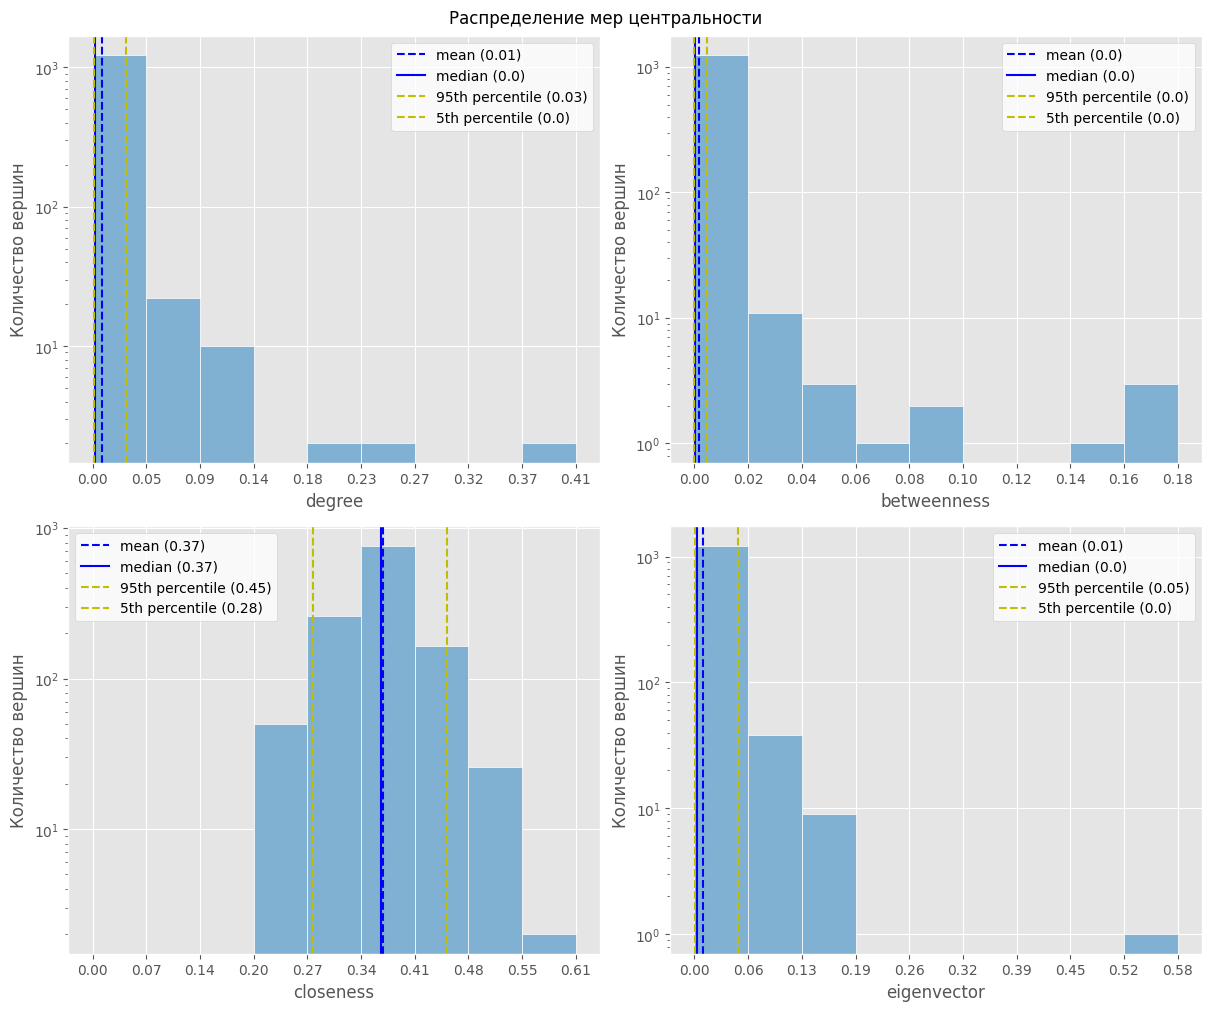

In [118]:
#@title Визуализируем распределения мер центральности
import matplotlib.ticker as ticker
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10), layout="constrained")
axes = axes.flatten()

# hub_centr = centralities[centralities.index.isin(hubs.index)].describe()

for i, column in enumerate(centralities.columns):
    col = centralities[column]
    bins = np.linspace(0, col.max()+0.01, 10)
    axes[i].hist(col, bins=bins, edgecolor='white', color=palette[4])

    axes[i].axvline(x=col.mean(), color='b', linestyle='--', label=f'mean ({round(col.mean(), 2)})')
    axes[i].axvline(x=col.median(), color='b', linestyle='-', label=f'median ({round(col.median(), 2)})')
    axes[i].axvline(x=col.quantile(0.95), color='y', linestyle='--', label=f'95th percentile ({round(col.quantile(0.95), 2)})')
    axes[i].axvline(x=col.quantile(0.05), color='y', linestyle='--', label=f'5th percentile ({round(col.quantile(0.05), 2)})')

    # axes[i].set_title(f'{column}')

    axes[i].set(xticks=bins)
    axes[i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:.2f}'))
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Количество вершин')
    axes[i].set_yscale('log')
    axes[i].legend(facecolor='white')

    # axes[i].axvspan(
    #     hub_centr[column]['min'],
    #     hub_centr[column]['max'],
    #     color=palette[3],
    #     alpha=0.05,
    #     zorder=0,
    # )

# plt.tight_layout()
plt.suptitle('Распределение мер центральности')
plt.show();


В сети наблюдаются околонулевые значения 95-го перцентиля для degree, betweenness и eigenvector. Это говорит о том, что большинство участников имеют небольшое количество прямых связей, через них редко проходят кратчайшие пути между другими участниками. При этом значение closeness для большинства лежит в промежутке от 0.29 до 0.45 -- участники не изолированы и, вероятно, связаны с остальной сетью посредством узкого круга хабов.

Далее рассмотрим участников, которые имеют наибольшие значения мер центральности.

In [119]:
# @title Высокие меры центральности
centr_measures = ['degree', 'betweenness', 'closeness', 'eigenvector']
outlier_coeffs = [5,5,3,5]
for m, c in zip(centr_measures, outlier_coeffs):
    threshold = get_upper_iqr_threshold(centralities[m], coeff=c)
    print()
    outliers = centralities[centralities[m]>threshold][m].sort_values(ascending=False)
    print(m, f': median={round(centralities[m].median(), 2)}, {len(outliers)} outliers: threshold={round(threshold,4)} (0.75th percentile + {c})')
    print('All shown are hubs:', all(outliers.head(10).index.isin(hubs.index)))
    print(outliers.head(10))


degree : median=0.0, 70 outliers: threshold=0.0246 (0.75th percentile + 5)
All shown are hubs: True
name
азамат мусагалиев    0.401269
денис дорохов        0.374306
гарик харламов       0.269627
дмитрий позов        0.251388
павел дедищев        0.194290
антон шастун         0.192704
алексей щербаков     0.133228
александр якушев     0.127676
расул чабдаров       0.124504
илья швецов          0.114195
Name: degree, dtype: float64

betweenness : median=0.0, 150 outliers: threshold=0.0006 (0.75th percentile + 5)
All shown are hubs: True
name
дмитрий позов        0.167766
азамат мусагалиев    0.163720
денис дорохов        0.160215
гарик харламов       0.143085
всеволод ловкачев    0.089369
павел дедищев        0.088012
расул чабдаров       0.064102
антон шастун         0.055848
алексей щербаков     0.050387
зоя яровицына        0.043127
Name: betweenness, dtype: float64

closeness : median=0.37, 4 outliers: threshold=0.5331 (0.75th percentile + 3)
All shown are hubs: True
name
азамат мус

В топ-10 по каждой мере центральности неизменно попадают Дмитрий Позов, Павел Дедищев с Азаматом Мусагалиевым и Денисом Дороховым в лидерах, в некоторых случаях со значительным отрывом от остальных. Все они -- ведущие нескольких (в том числе и продолжительных) проектов с участием гостей, которые также часто появляются в других проектах в качестве гостя (входят в топ-30).


degree--degree rho = 1.0 p-value = 0.0
degree--betweenness rho = 0.8711 p-value = 0.0
degree--closeness rho = 0.738 p-value = 1.8683205402539364e-217
degree--eigenvector rho = 0.7961 p-value = 4.313407087187133e-277


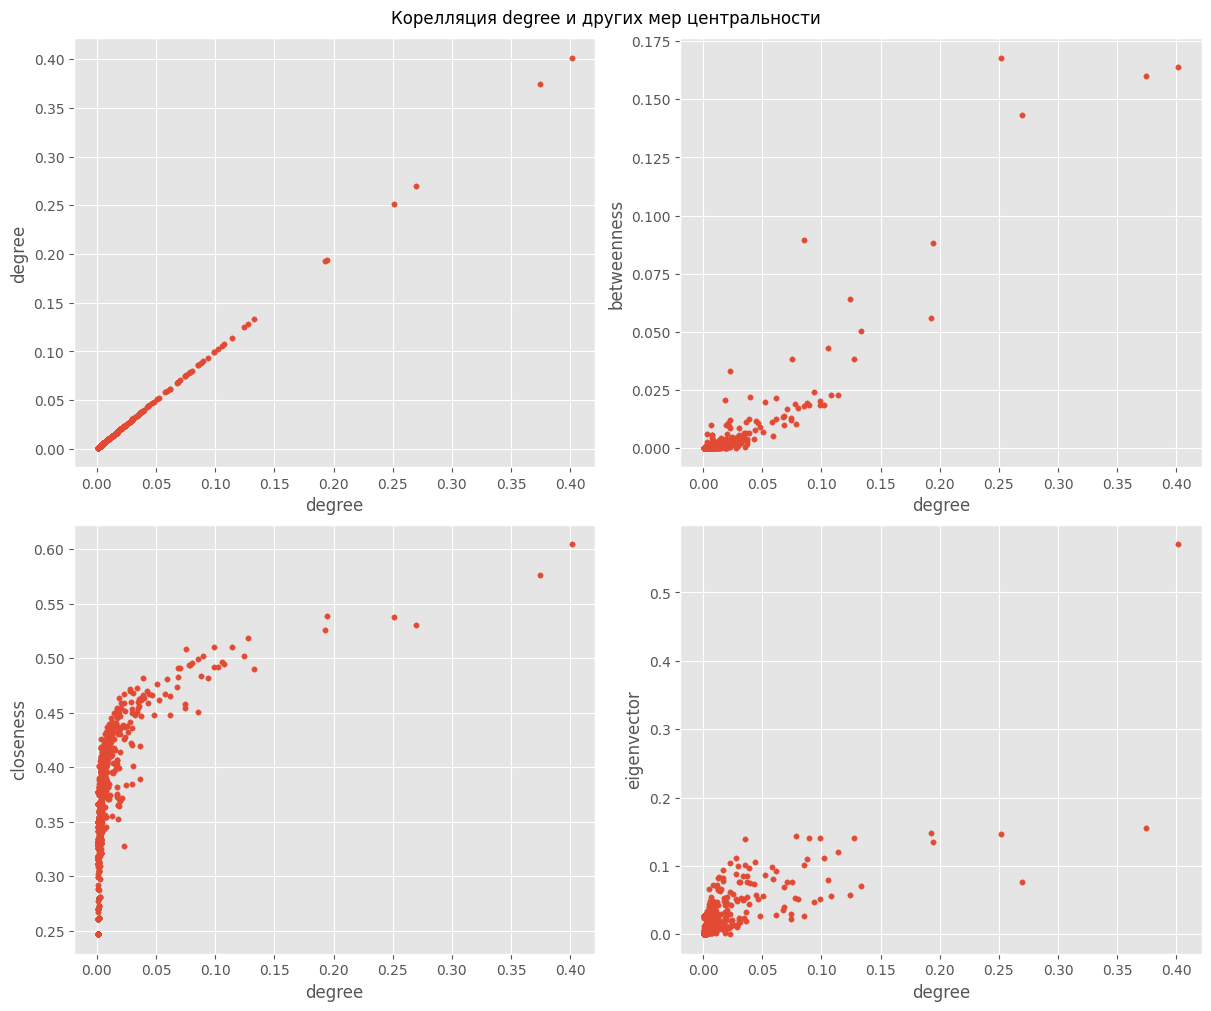

In [120]:
# @title Корелляция мер центральности
from scipy import stats
centr_measures = ['degree', 'betweenness', 'closeness', 'eigenvector']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10), layout='constrained')
axes = axes.flatten()
for i, m in enumerate(centr_measures):

    s = centralities[m]
    axes[i].scatter(x=centralities['degree'], y=s, s=15, linewidths=0.3)
    axes[i].set(xlabel='degree', ylabel=m)

    res = stats.spearmanr(centralities['degree'], s)
    print(f'{'degree'}--{m}', 'rho =', round(res.statistic,4), 'p-value =', res.pvalue)
plt.suptitle('Корелляция degree и других мер центральности');

Из графика распределений мер центральности и значений корреляции мы видим, что чем больше степень вершины, тем выше любая другая мера центральности. Это в очередной раз говорит о том, что те немногие, которые имеют наибольшее количество связей, выполняют роль "общих" звеньев, которые связывают другие вершины сети -- через такие хабы осуществляется взаимодействие.

In [121]:
# @title Ассортативность по степени вершин
# @markdown Предпочитают ли хабы связываться с другими хабами или же наоборот -- с вершинами, имеющими мало связей. Положительный коэффициент означает связь с подобными себе.
r = nx.degree_assortativity_coefficient(G, weight='count')

print(f"Ассортативность по степени вершин: {r:3.1f}")

Ассортативность по степени вершин: -0.2


Значение ассортативности близко к нулю, что означает слабую зависимость вероятности присоединения от степени вершины, или небольшую склонность вершин с высокой степенью присоединяться к вершиной с низкой степенью.

### Определение сообществ

Рассмотрим сообщества, определенные на основе совместных появлений в выпусках, опубликованных в 2025 году

In [122]:
#@title Определяем сообщества для участников выпусков 2025 года
import itertools
from collections import Counter
# создаем граф для 2025 года
#@title Подготавливаем список ребер
hosts_2025 = df[df['date']>='2025-01-01']['hosts_str'].dropna().str.split(',').explode().str.strip().rename('left')
guests_2025 = df[df['date']>='2025-01-01']['guests_full'].explode().str.strip().rename('right')
interactions_2025 = pd.merge(left=hosts_2025, right=guests_2025, left_index=True, right_index=True, how='inner')
interactions_2025.drop(interactions_2025[interactions_2025['left']==interactions_2025['right']].index, inplace=True)

print('Количество парных взаимодействий (в т.ч. повторных): ', len(interactions_2025))
print('Количество уникальных пар: ', len(interactions_2025.drop_duplicates()))
interactions_2025 = interactions_2025.value_counts().reset_index()
# Создаем граф
G_2025 = nx.from_pandas_edgelist(
    df=interactions_2025,
    source='left',
    target='right',
    edge_attr=['count'],
    # create_using=nx.MultiDiGraph,
)
print(G_2025)

Количество парных взаимодействий (в т.ч. повторных):  3360
Количество уникальных пар:  2063
Graph with 563 nodes and 1997 edges


In [123]:
# @title Функция для визуализации сообществ
def visualize_community(com_number, com_set, title=None, annotated_degree_min_threshold=0, dims=(20,20)):
    """
    Визуализировать вершины и связи внутри конкретного сообщества. Добавить подписи для топ-20 в сообществе по степени вершины, покрасить красным хабы
    """
    cur_comm = com_set[com_number]

    # edgelist_sub = [e for e in edges if e[0] in cur_comm or e[1] in cur_comm] # включаем членов сообщества + всех, кто снимался с ними хотя бы раз
    edgelist_sub = [(e[0], e[1]) for e in interactions_2025.values if e[0] in cur_comm and e[1] in cur_comm] # включаем только членов сообщества
    # print(edgelist_sub)

    G_sub = nx.from_edgelist(edgelist_sub)
    print(G_sub)

    # 3. Process the results for visualization
    # Create a dictionary to map each node to its community ID
    node2color = {}
    for pair in G_sub.edges:
        for node in pair:
            if node in hubs:
                node2color[node] = 'red'
            else:
                node2color[node] = 'blue'

    # Get a list of community IDs in the order of the nodes
    node_colors = [node2color[node] for node in G_sub.nodes()]

    # pos = nx.kamada_kawai_layout(G_sub)
    pos = nx.forceatlas2_layout(G_sub, scaling_ratio=100)

    top_20 = list(dict(sorted(dict(G_sub.degree).items(), key=lambda x: x[1], reverse=True)[:20]).keys())

    labels = {}
    for node in G_sub.nodes():
        if node in cur_comm and node in top_20:
            labels[node] = node


    plt.figure(figsize=dims)

    nx.draw_networkx_nodes(G_sub, pos, node_size=[x*10 + 20 for x in dict(G_sub.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
    nx.draw_networkx_edges(G_sub, pos, arrows=True, edge_color='gray', alpha=0.3) #  width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_sub, 'count').values())]
    nx.draw_networkx_labels(G_sub, pos,labels,font_size=9,font_color='black')

    if not title:
        title = f"Сообщество {com_number}"
    plt.title(title)
    # plt.legend()
    plt.show();

#### Clauset-Newman-Moore Greedy Modularity Maximization

Модулярность сравнивает количество ребер внутри сообществ с тем, что ожидается в случайной сети с тем же распределением степеней.

In [124]:
# @title Определяем сообщества
comm_greedy = list(nx.algorithms.community.greedy_modularity_communities(G_2025))
print('Количество сообществ по Clauset-Newman-Moore Greedy Modularity Maximization:', len(comm_greedy))
modularity_score = nx.community.modularity(G_2025, comm_greedy, weight="weight")
print('Модулярность по Clauset-Newman-Moore Greedy Modularity Maximization', round(modularity_score,2))

Количество сообществ по Clauset-Newman-Moore Greedy Modularity Maximization: 5
Модулярность по Clauset-Newman-Moore Greedy Modularity Maximization 0.44


Значение модулярности 0.44 говорит о том, что внутри сообщества наблюдается больше связей, чем ожидается в случайном графе; существуют сообщества, но при этом сеть не фрагментирована.

In [125]:
# @title Формируем граф
# #@markdown Оставляем только вершины, которые находятся в пределах 75-го перцентиля по количеству прямых связей

# degrees = pd.Series(dict(G_2025.degree()))
# threshold = degrees.quantile(0.75)  # for example

# keep_nodes = degrees[degrees >= threshold].index
# G_vis = G_2025.subgraph(keep_nodes)

# print(f"Изначальное количество вершин: {G_2025.number_of_nodes()}")
# print(f"Количество вершин в сокращенном графе: {G_vis.number_of_nodes()}")
# print(f"Минимальная степень вершины: {threshold}")

pos = nx.kamada_kawai_layout(G_2025, scale=5)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



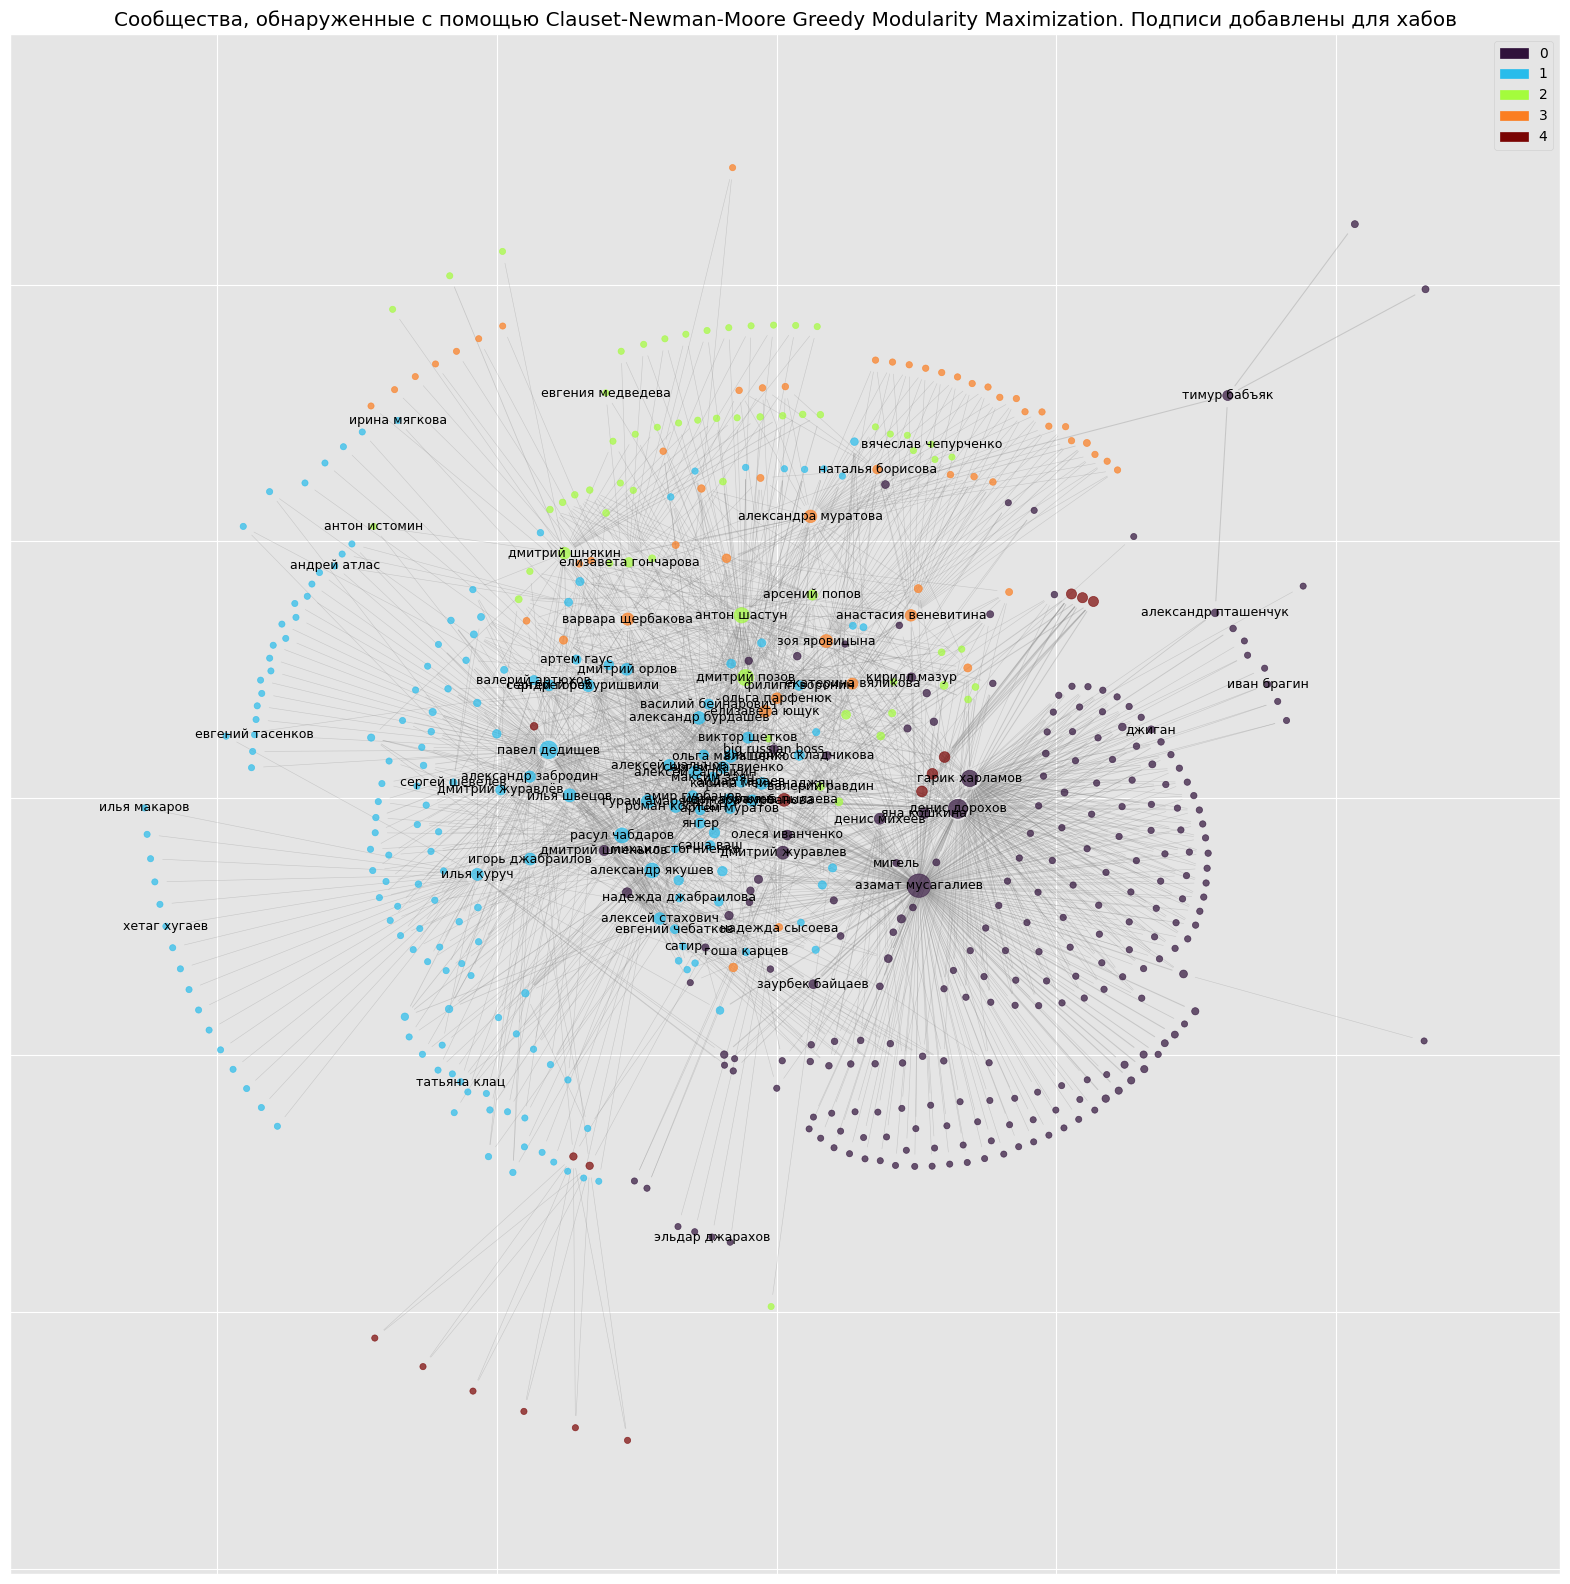

In [126]:
# @title Визуализация сообществ, обнаруженных с помощью Clauset-Newman-Moore Greedy Modularity Maximization
import matplotlib.patches as mpatches
node_to_community = {}
for i, comm in enumerate(comm_greedy):
    for node in comm:
        node_to_community[node] = i

# создаем палитру по числу сообществ
cmap = plt.colormaps['turbo'].resampled(len(comm_greedy))

# назначаем цвет каждой вершине
cat_colors = dict(zip(list(range(len(comm_greedy))), cmap.colors))
node_colors = (pd.Series({n: cat_colors[comm_i] for comm_i, nodes in enumerate(comm_greedy) for n in nodes})
 .reindex(G_2025.nodes)
)

# рисуем граф
labels = {}
for node in G_2025.nodes():
    if node in hubs:
        labels[node] = node

edges_to_draw = []
for e in G_2025.edges:
    if e[0] != e[1]:
        edges_to_draw.append(e)
plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_2025, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_2025.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
nx.draw_networkx_edges(G_2025, pos, edgelist=edges_to_draw, arrows=True, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_2025, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_2025, pos,labels,font_size=9,font_color='black')

plt.legend(handles=[mpatches.Patch(color=c, label=label)
                    for label, c in cat_colors.items()],
           bbox_to_anchor=(1, 1))

plt.title("Сообщества, обнаруженные с помощью Clauset-Newman-Moore Greedy Modularity Maximization. Подписи добавлены для хабов")
plt.show();

Поскольку визуализацию выше довольно сложно читать, покажем сообщества отдельно.

In [127]:
# @title Сообщества, обнаруженные алгоритмом Clauset-Newman-Moore Greedy Modularity Maximization
print(f"Обнаружено {len(comm_greedy)} сообществ:")
for i, comm in enumerate(comm_greedy):
    print(f"Сообщество №{i}\t({len(comm)} человек):\t Хабы: {', '.join(list(filter(lambda x: x in hubs, comm)))}")
    # print(f"Сообщество №{i}\t({len(comm)} человек)")

Обнаружено 5 сообществ:
Сообщество №0	(236 человек):	 Хабы: иван брагин, джиган, мигель, тимур бабъяк, big russian boss, олеся иванченко, эльдар джарахов, азамат мусагалиев, денис михеев, дмитрий журавлев, заурбек байцаев, яна кошкина, гарик харламов, кирилл мазур, денис дорохов, дмитрий шпеньков, александр пташенчук
Сообщество №1	(193 человек):	 Хабы: гоша карцев, янгер, валерий артюхов, евгений тасенков, татьяна клац, артем муратов, максим заяц, артем гаус, надежда джабраилова, игорь джабраилов, саша ваш, илья куруч, михаил стогниенко, айдар гараев, василий бейнарович, павел дедищев, гурам амарян, динара курбанова, филипп воронин, илья швецов, расул чабдаров, александр забродин, карина мейханаджян, александр якушев, амир гурбанов, сергей матвиенко, роман косицын, евгений чебатков, алексей сапрыкин, илья макаров, сергей горох, сергей шевелев, виктория складчикова, сатир, ирина мягкова, андрей бебуришвили, дмитрий журавлёв, алексей стахович, алексей шальнов, ольга малащенко, андрей атл

Алгоритм обнаружил 2 особенно крупных сообщества.

Визуализируем сообщества и подпишем топ-20 ее членов по степени вершины. Красным выделены хабы.

Graph with 55 nodes and 152 edges


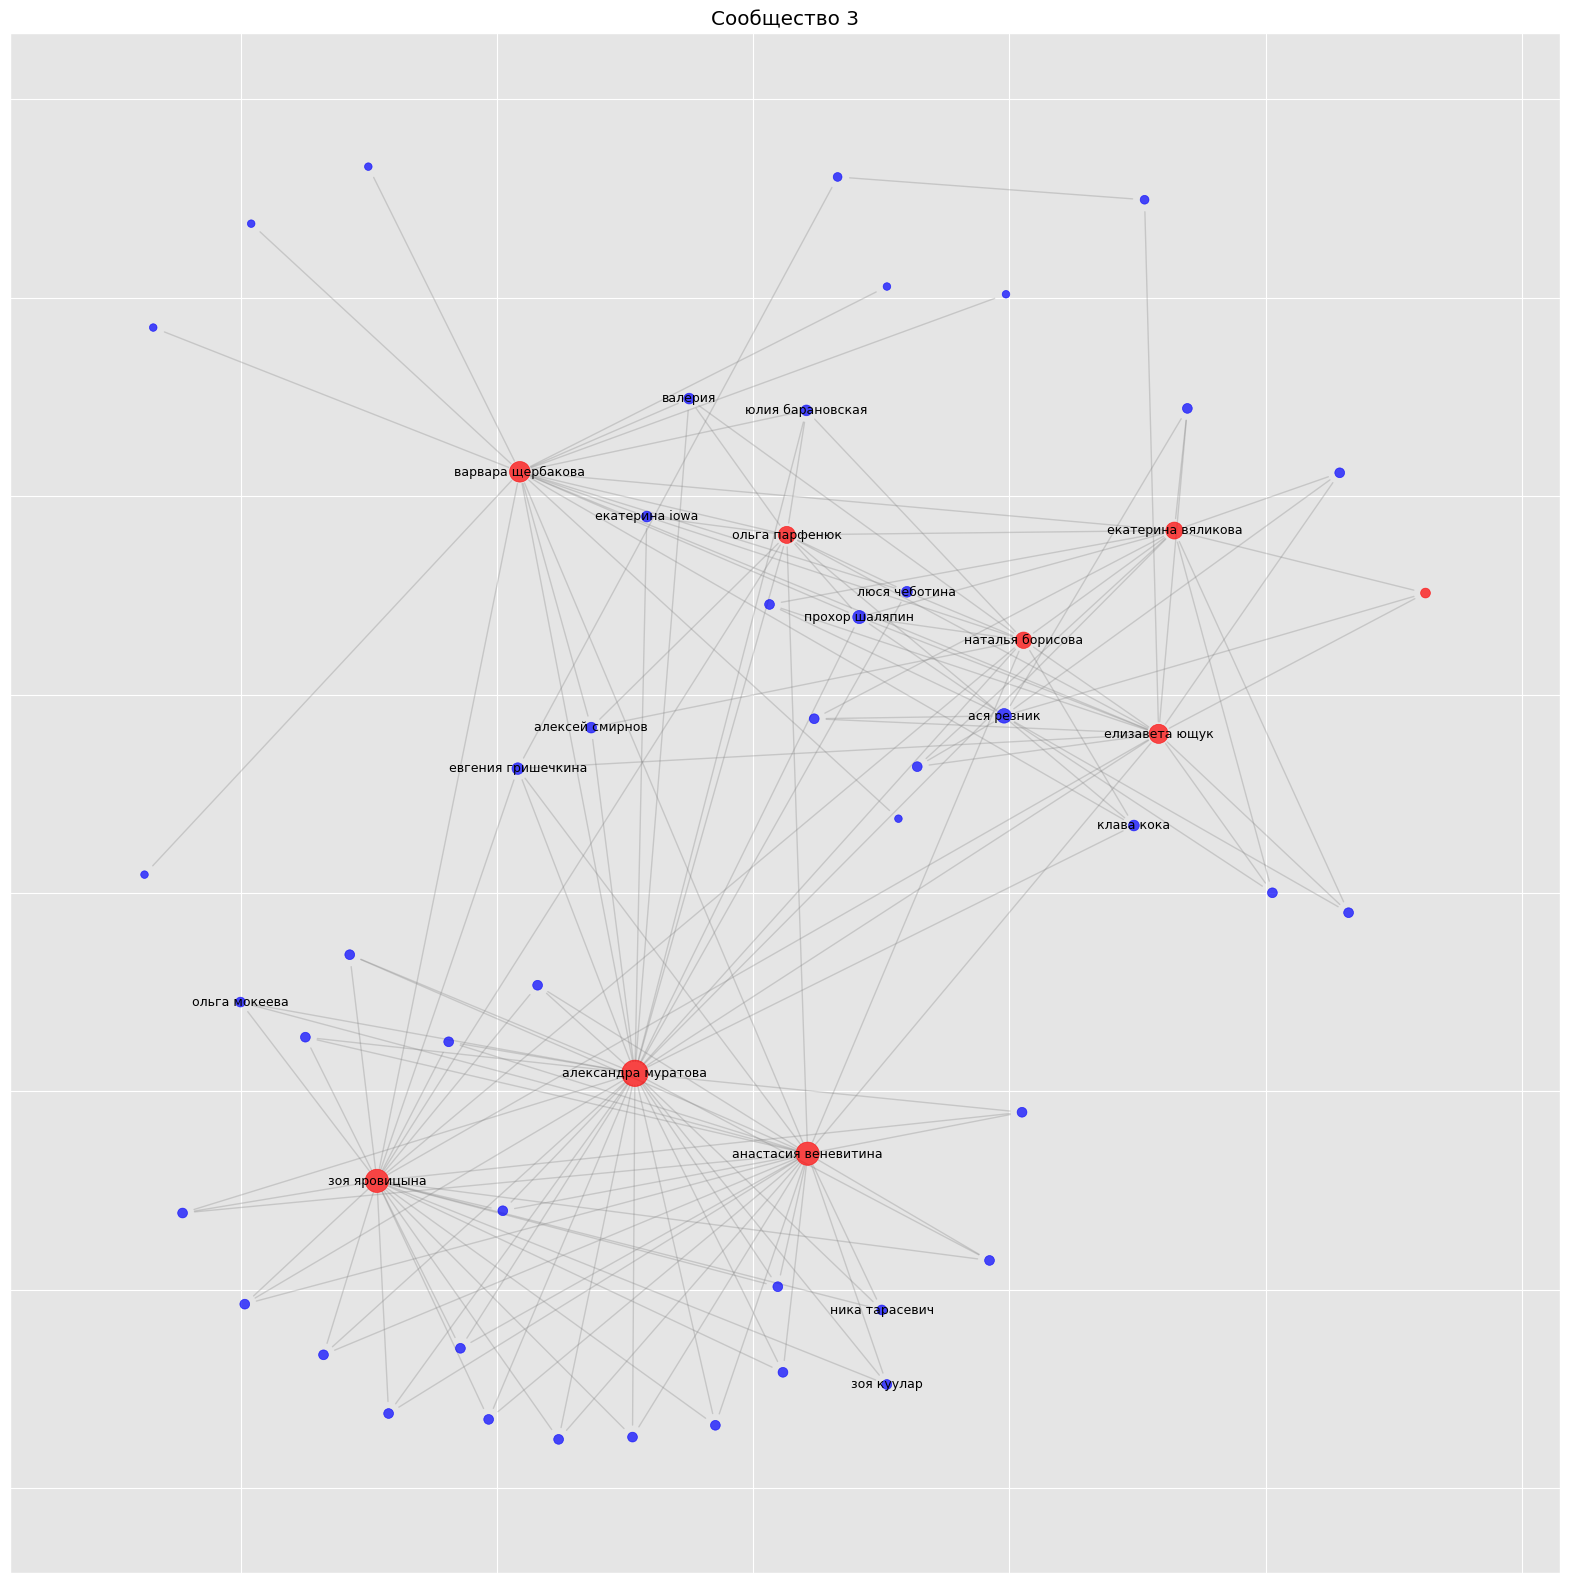

In [128]:
#@title Визуализация конкретных сообществ
COMMUNITY_NUM = 3 # @param {"type":"integer"}

visualize_community(COMMUNITY_NUM, comm_greedy, annotated_degree_min_threshold=hub_degree_threshold)

Сообщество 3 состоит по большей части из женщин: комикесс, актрис, певиц. В числе хабов -- Варвара Щербакова, Ольга Парфенюк, Александра Муратова и Наталья Борисова -- ведущие шоу "Женский форум".

TODO: 🤔 Преобладание женщин в сообществе наводит на идею проверить сеть на атрибутивную ассортативность.

#### Louvain method

In [129]:
#@title Определяем сообщества
comm_louvian = nx.community.louvain_communities(G, weight='count', seed=42)
print('Количество сообществ по Louvain method:', len(comm_louvian))
# считаем модулярность
modularity_score = nx.community.modularity(G, comm_louvian, weight='count')
print('Модулярность по Louvain method', round(modularity_score,2))

Количество сообществ по Louvain method: 9
Модулярность по Louvain method 0.38


Значение модулярности ниже, чем для предыдущего алгоритма, что говорит о менее четкой сформированности сообществ.

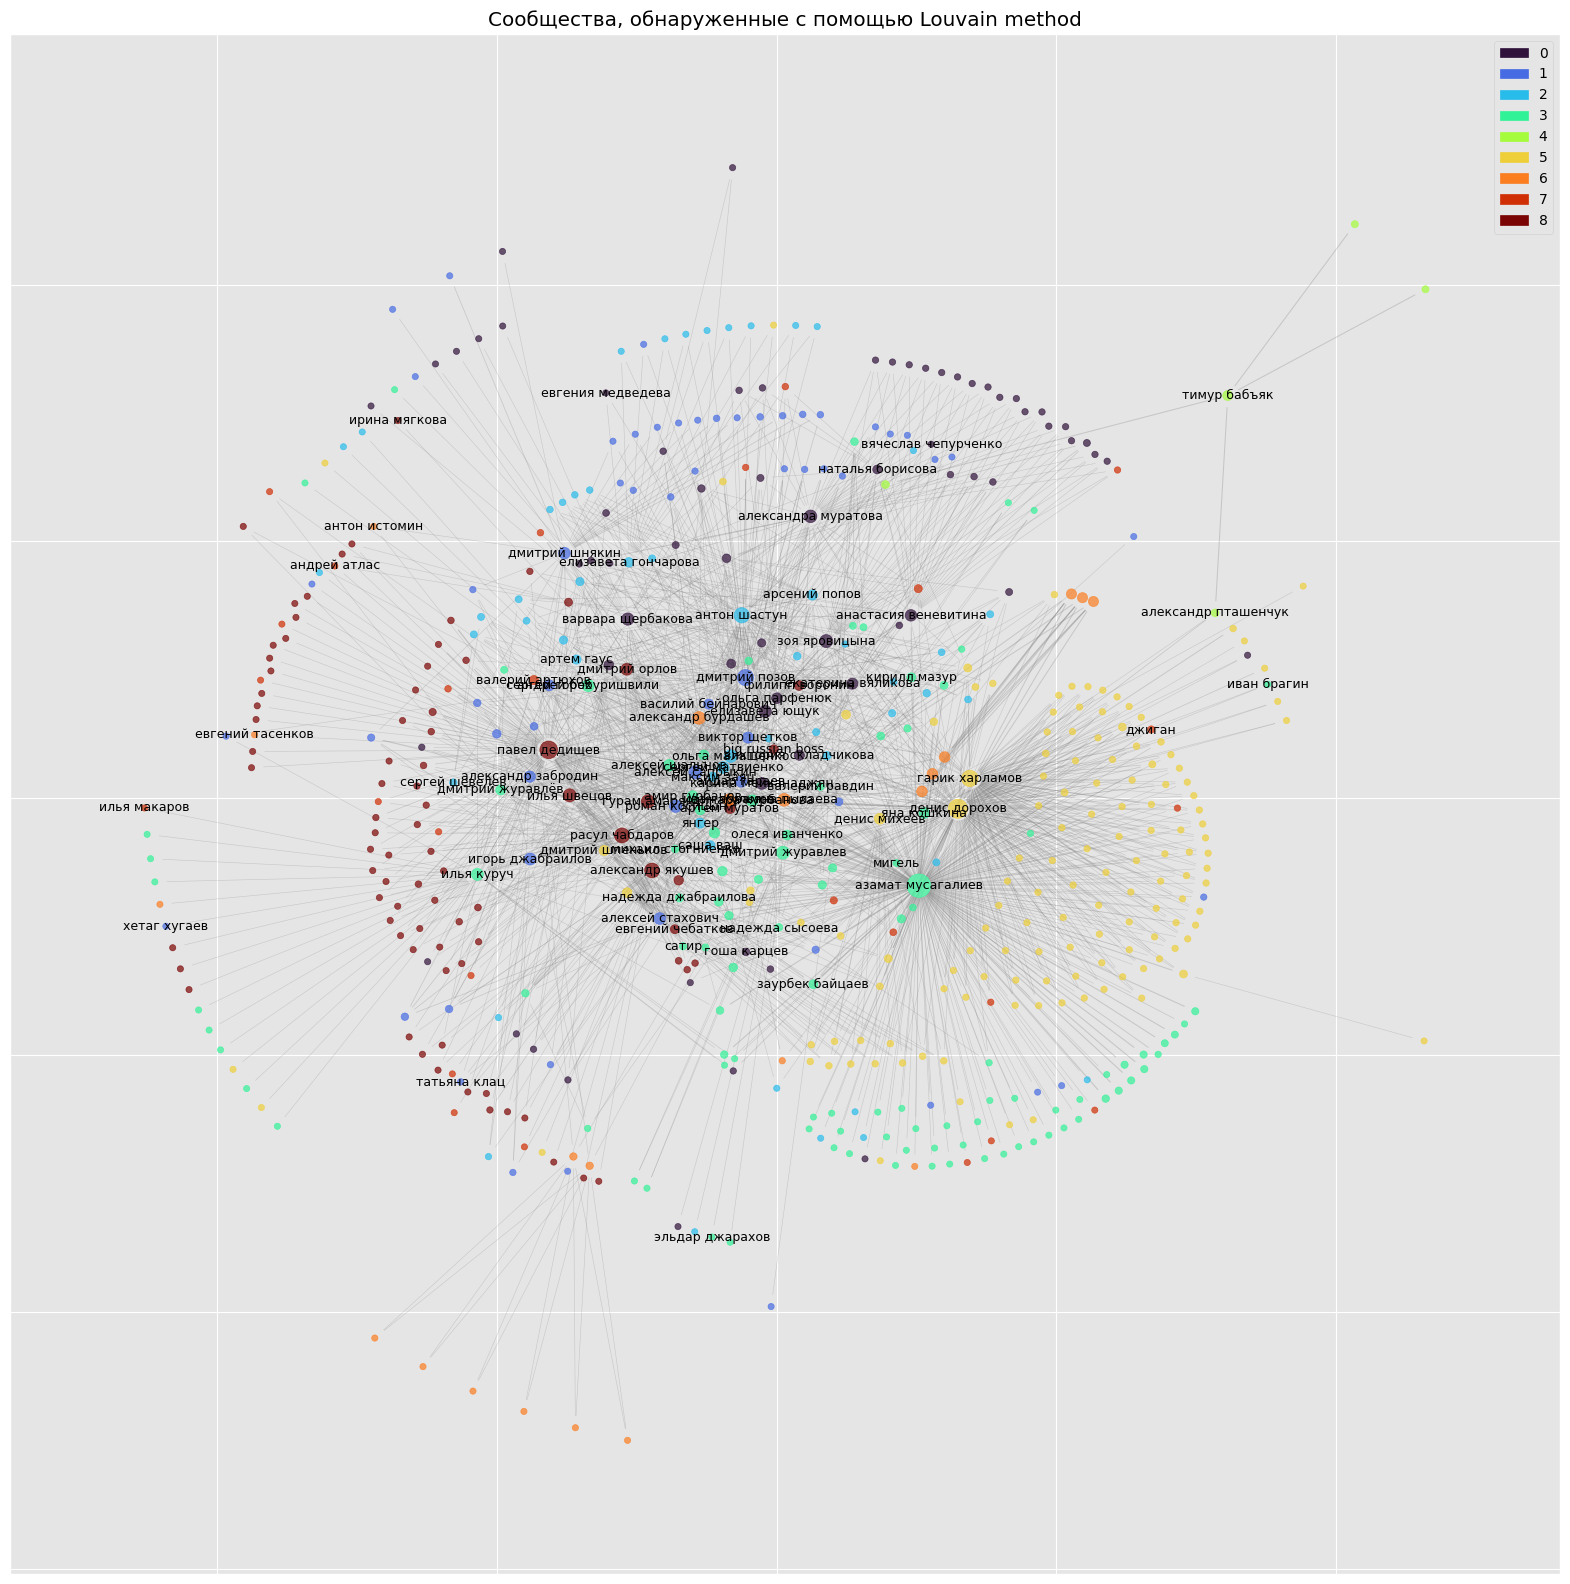

In [130]:
# @title Визуализация сообществ, обнаруженных с помощью Louvain method
node_to_community = {}
for i, comm in enumerate(comm_louvian):
    for node in comm:
        node_to_community[node] = i

# создаем палитру по числу сообществ
cmap = plt.colormaps['turbo'].resampled(len(comm_louvian))

# назначаем цвет каждой вершине
cat_colors = dict(zip(list(range(len(comm_louvian))), cmap.colors))
node_colors = (pd.Series({n: cat_colors[comm_i] for comm_i, nodes in enumerate(comm_louvian) for n in nodes})
 .reindex(G_2025.nodes)
)

# рисуем граф
labels = {}
for node in G_2025.nodes():
    if node in hubs:
        labels[node] = node

edges_to_draw = []
for e in G_2025.edges:
    if e[0] != e[1]:
        edges_to_draw.append(e)
plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_2025, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_2025.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
nx.draw_networkx_edges(G_2025, pos, edgelist=edges_to_draw, arrows=True, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_2025, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_2025, pos,labels,font_size=9,font_color='black')

plt.legend(handles=[mpatches.Patch(color=c, label=label)
                    for label, c in cat_colors.items()],
           bbox_to_anchor=(1, 1))

plt.title("Сообщества, обнаруженные с помощью Louvain method")
plt.show();

In [131]:
# @title Сообщества, обнаруженные алгоритмом Louvain
print(f"Обнаружено {len(comm_louvian)} сообществ:")
for i, comm in enumerate(comm_louvian):
    print(f"Сообщество №{i}\t({len(comm)} человек):\t Хабы: {', '.join(list(filter(lambda x: x in hubs, comm)))}")
    # print(f"Сообщество №{i}\t({len(comm)} человек)")

Обнаружено 9 сообществ:
Сообщество №0	(135 человек):	 Хабы: гоша карцев, елизавета ющук, анастасия веневитина, варвара щербакова, вячеслав чепурченко, наталья борисова, евгения медведева, карина мейханаджян, екатерина вяликова, ольга парфенюк, александра муратова, виктория складчикова, зоя яровицына
Сообщество №1	(160 человек):	 Хабы: татьяна клац, игорь джабраилов, айдар гараев, василий бейнарович, александр забродин, роман косицын, алексей сапрыкин, сергей горох, дмитрий позов, дмитрий шнякин, алексей стахович, хетаг хугаев, виктор щетков
Сообщество №2	(107 человек):	 Хабы: елизавета гончарова, янгер, сергей матвиенко, максим заяц, сергей шевелев, антон шастун, артем гаус, серафим фарботко, саша ваш, илья шалашов, ольга малащенко, арсений попов
Сообщество №3	(142 человек):	 Хабы: иван брагин, надежда джабраилова, илья куруч, мигель, михаил стогниенко, валерий равдин, динара курбанова, олеся иванченко, эльдар джарахов, азамат мусагалиев, амир гурбанов, дмитрий журавлев, заурбек байцае

Graph with 39 nodes and 86 edges


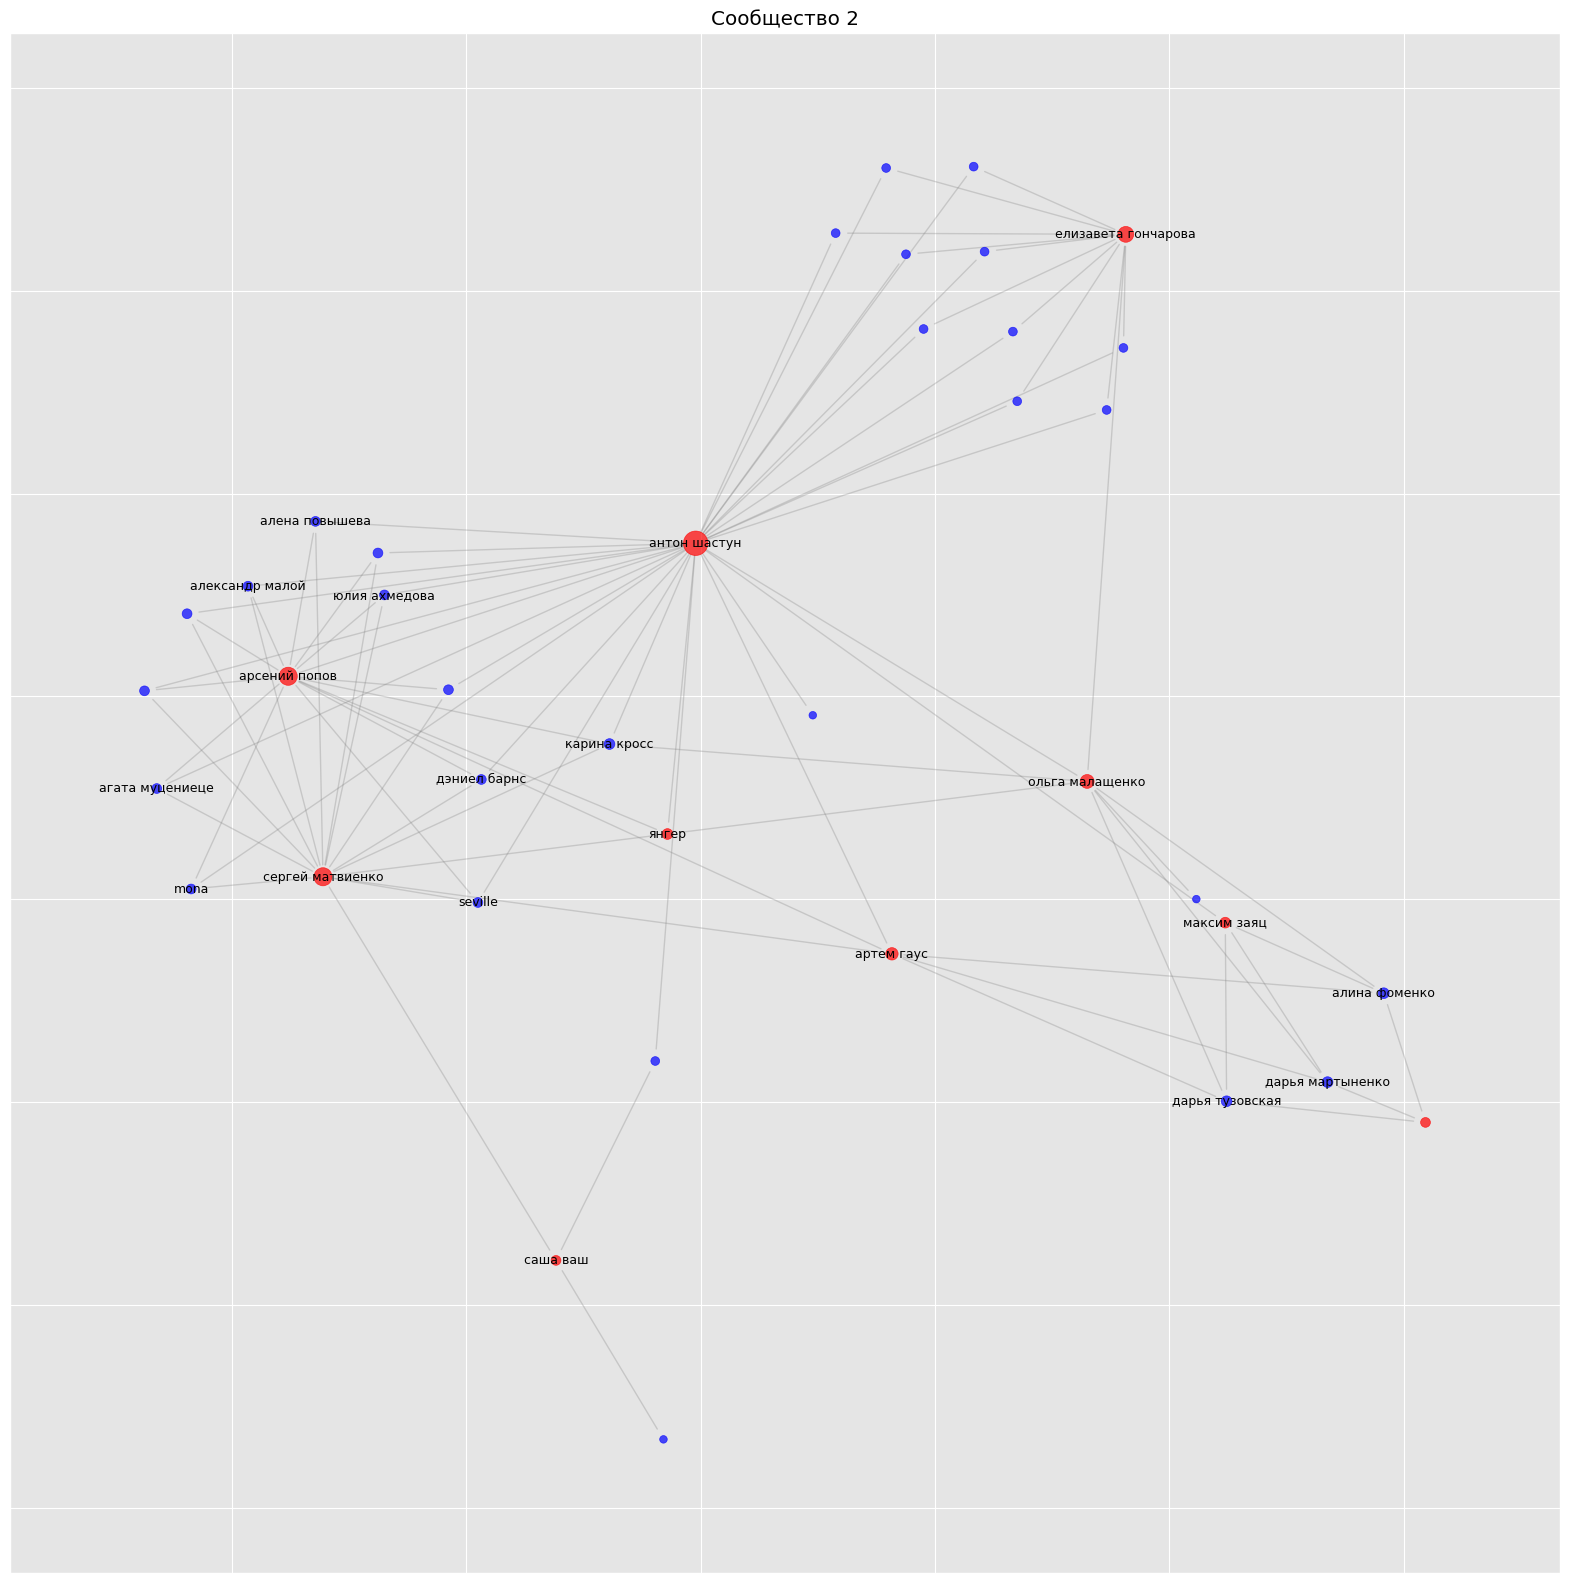

In [132]:
# @title Визуализация конкретных сообществ
COMMUNITY_NUM = 2 # @param {"type":"integer"}

visualize_community(COMMUNITY_NUM, comm_louvian)

In [133]:
# @title Выявление клик
from collections import Counter
min_shared_shows = 10

G_strong = nx.Graph()

for i, row in interactions.iterrows():
    u, v, count = row['left'], row['right'], row['count']
    if count >= min_shared_shows:
        G_strong.add_edge(u, v, weight=count)

# найти максимальные клики
cliques = list(nx.find_cliques(G_strong))

# Оставить только клики, где больше 5 людей
clique_size = 3
large_cliques = [clique for clique in cliques if len(clique) >= clique_size]

print(f"Клик, в которых {clique_size} членов и более: {len(large_cliques)}")

pers_cliques = Counter()
print('Обнаруженные клики')
for c in large_cliques:
    print(c)
    pers_cliques.update(c)

Клик, в которых 3 членов и более: 13
Обнаруженные клики
['татьяна клац', 'алексей сапрыкин', 'дмитрий позов']
['азамат мусагалиев', 'игорь джабраилов', 'роман косицын']
['азамат мусагалиев', 'игорь джабраилов', 'алексей стахович']
['азамат мусагалиев', 'игорь джабраилов', 'алексей сапрыкин', 'антон шастун']
['азамат мусагалиев', 'игорь джабраилов', 'алексей сапрыкин', 'дмитрий позов']
['азамат мусагалиев', 'евгений чебатков', 'павел дедищев']
['азамат мусагалиев', 'павел дедищев', 'гурам амарян']
['азамат мусагалиев', 'денис дорохов', 'зоя яровицына']
['азамат мусагалиев', 'зоя яровицына', 'антон шастун']
['сергей горох', 'игорь джабраилов', 'роман косицын']
['сергей горох', 'игорь джабраилов', 'алексей стахович']
['сергей горох', 'игорь джабраилов', 'антон шастун']
['сергей горох', 'игорь джабраилов', 'дмитрий позов']


Клики -- это группы участников, в которых каждая пара взаимодействовала хотя бы раз. В силу строгости определения, клики менее интуитивно понятны. Поэтому клики используются как локальные индикаторы плотного сотрудничества. В то же время сообщества выявляют более широкие группы часто взаимодействующих участников.

## Кто входит в круг "популярных"?
Выше мы показали, что участие в шоу действительно распределено очень неравномерно, и небольшой круг людей появляется в шоу продакшена значительно чаще остальных и имеет значительно больше прямых связей, чем остальные. Однако лидеры разных показателей отличаются.

Ниже -- попытка выделить круг самых активных участников, опираясь на количество выпусков и шоу, в которых появлялись участники, степень вершины и меры центральности. Будем считать "популярными" участников, которые входят в топ-5% по количеству шоу, в которых они участвовали, и в топ-1% хотя бы по 2 из 4 критериям: количество выпусков, степень вершины, betweeness и eigenvector.

In [155]:
# @title Определение "популярных" участников
total_stats = total_stats.fillna(0)
columns = [
# 'episodes_total',
 'shows_total',
 'degree_abs',
 'betweenness',
#  'closeness',
 'eigenvector']

# top-1%
threshold = 0.99
for c in columns:
    total_stats[f"{c}_top10"] = (
        total_stats[c] >= total_stats[c].quantile(threshold)
    )

# top-5%
total_stats[f"shows_total_top10"] = (
        total_stats['shows_total'] >= total_stats['shows_total'].quantile(0.95)
    )

total_stats["n_top10_measures"] = total_stats[
    [f"{c}_top10" for c in columns]
].sum(axis=1)

leaders = total_stats[(total_stats["n_top10_measures"] >= 2) & (total_stats['shows_total_top10']==True)]

print(f"Популярные участники: {len(leaders)}")
print(*leaders.index, sep='\n')

Популярные участники: 21
азамат мусагалиев
александр якушев
александра муратова
алексей шальнов
андрей бебуришвили
антон шастун
арсений попов
варвара щербакова
гарик харламов
гурам амарян
денис дорохов
дмитрий журавлев
дмитрий позов
евгений чебатков
зоя яровицына
игорь джабраилов
илья швецов
павел дедищев
расул чабдаров
саша ваш
сергей матвиенко
